# Missing Data and Statistical Inference

**Question.** When some values are missing, how much does the way we handle them change a regression estimate — and how far can we trust its confidence interval?

**Set-up.** The data are simulated from a known model, so the right answer is known:

`Y = 5 + 2·X1 − 1.5·X2 + 1·X3 + ε`  — the focus is **β₁ = 2**.

About 20% of the values of **Y** and of **X1** are then deleted under three missingness mechanisms (**MCAR, MAR, MNAR**), and the regression is re-estimated after handling the gaps in eight different ways.

| Method | What it does | Uses Z? |
|---|---|---|
| Complete Case | drop every row that has a missing value | no |
| Mean Imputation | fill each gap with the column mean | no |
| Hot-Deck | copy the value from the most similar complete row | yes |
| Regression Imputation | fill each gap with its predicted value | yes |
| Stochastic Regression | predicted value + a random residual | yes |
| MICE (normal) | several random regression imputations, combined with Rubin's rules | yes |
| MICE (PMM) | same, but the filled-in values are real values borrowed from similar rows | yes |
| EM | maximum likelihood for the means and covariances of all variables | yes |

**Z is an auxiliary variable**: a noisy copy of Y (`Z = Y + noise`). It is *not* in the regression model, but it is observed for everyone and can help to fill in the gaps.

**How the comparison is organised.** Everything is compared **within each missingness mechanism**: for MCAR, then MAR, then MNAR we ask *which way of handling the gaps works best?* We do not rank the mechanisms against each other.

**Three kinds of confidence interval are compared.** For every method we build the intervals an analyst would actually use: the **classical** interval (estimate ± 1.96 × formula SE), two **bootstrap** intervals (the *standard* one, estimate ± 1.96 × bootstrap SE, and the *percentile* one), and for MICE the **Rubin** interval. Whether an interval can be trusted is judged by its **coverage**: how often it contains the true value 2.

**Bootstrap and Monte Carlo are two different things, and both are used.**
* The **bootstrap** resamples the rows of *one* dataset to produce *one* confidence interval. It does not know the true population.
* **Monte Carlo** draws *many new datasets from the true population*. Only Monte Carlo can tell us how often an interval contains the truth.

So the bootstrap runs **inside** the Monte Carlo: for each of `N_REPS` simulated datasets, every method is bootstrapped `B_BOOT` times (N × B replication), giving one interval per dataset; then we count how many of the `N_REPS` intervals contain 2.

**How the notebook is organised — every step is its own block**

1. Setup
2. Simulate the complete data
3. The analysis model (the regression every method ends with)
4. Create the missing data: MCAR, MAR, MNAR
5. **The eight methods, step by step** — on one dataset, to *see* what each method does (illustration only, no conclusions)
6. **Building confidence intervals** — classical, bootstrap and Rubin intervals on one dataset, and why one interval cannot tell us whether a method works
7. **The Monte Carlo study** — `N_REPS` new datasets × every mechanism × every method, with `B_BOOT` bootstrap resamples inside each
8. **Results, one mechanism at a time** — bias, accuracy and the coverage of every type of interval
9. Master tables, findings, limitations and conclusion

## 1. Setup

In [1]:
# ===== Step 1a — Libraries =====
# If a package is missing, uncomment the next line:
# !pip install numpy pandas scipy scikit-learn statsmodels matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.special import expit
from sklearn.impute import KNNImputer
from IPython.display import display, Markdown

In [2]:
# ===== Step 1b — Settings you can change =====
from pathlib import Path

SEED = 42                                      # seed for the one-dataset walkthrough (Sections 2-6)
N = 200                                        # observations per dataset
TRUE_BETA = np.array([5.0, 2.0, -1.5, 1.0])    # intercept, X1, X2, X3
M_IMPUTATIONS = 10                             # number of imputed datasets in MICE

N_REPS = 300                                   # Monte Carlo repetitions (new datasets from the true model)
B_BOOT = 200                                   # bootstrap resamples inside EVERY simulated dataset
MC_SEED = 2024                                 # seed for the Monte Carlo study
N_JOBS = -1                                    # CPU cores for the simulation: -1 = all cores, 1 = no parallel computing
USE_SAVED_RESULTS = True                       # reuse saved simulation results if they exist with these same settings
# Quick test: set N_REPS = 20 and B_BOOT = 50 (takes about a minute).
# The full study (300 x 200) takes roughly 40 minutes on one core, less with several cores.

MECHANISMS = ["MCAR", "MAR", "MNAR"]
METHOD_ORDER = ["Complete Case", "Mean Imputation", "Hot-Deck", "Regression Imputation",
                "Stochastic Regression", "MICE (normal)", "MICE (PMM)", "EM"]

# results are saved next to the notebook (or in the repository's results/ folder)
RESULTS_DIR = Path("../results") if Path("../results").is_dir() else Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
print("Results folder:", RESULTS_DIR.resolve())

Results folder: /home/claude/v5/full/results


## 2. Simulating the complete data

* **X1, X2, X3** are independent standard normal.
* **Y** follows the model above with N(0, 1) noise.
* **Z = Y + noise** is the auxiliary variable (never in the regression, never missing).

In [3]:
# ===== Step 2a — Function that creates one complete dataset =====
def make_data(rng, n=N):
    """One complete dataset: predictors X1-X3, outcome Y, auxiliary variable Z."""
    X = rng.normal(size=(n, 3))
    Y = TRUE_BETA[0] + X @ TRUE_BETA[1:] + rng.normal(size=n)
    Z = Y + rng.normal(size=n)                      # noisy copy of Y (not part of the regression)
    return pd.DataFrame(np.column_stack([X, Z, Y]), columns=["X1", "X2", "X3", "Z", "Y"])

In [4]:
# ===== Step 2b — Create the complete dataset used in the walkthrough (Sections 2-6) =====
rng = np.random.default_rng(SEED)
full = make_data(rng)

print("Shape:", full.shape)
full.head()

Shape: (200, 5)


,X1,X2,X3,Z,Y
0,0.304717,-1.039984,0.750451,7.590227,8.435272
1,0.940565,-1.951035,-1.302180,6.844265,7.927964
2,0.127840,-0.316243,-0.016801,7.332296,6.987691
3,-0.853044,0.879398,0.777792,2.504300,2.125020
4,0.066031,1.127241,0.467509,4.559425,3.272094


In [5]:
# ===== Step 2c — Summary statistics =====
full.describe().round(2)

,X1,X2,X3,Z,Y
count,200.00,200.00,200.00,200.00,200.00
mean,-0.00,-0.08,0.00,5.04,5.07
std,1.01,0.97,0.94,2.91,2.72
min,-2.96,-2.41,-2.57,-1.49,-1.79
25%,-0.71,-0.80,-0.60,2.82,3.03
50%,-0.07,-0.08,0.13,4.83,4.96
75%,0.67,0.46,0.54,7.19,6.97
max,2.33,2.91,2.91,13.12,12.73


In [6]:
# ===== Step 2d — Correlations (note how strongly Z follows Y) =====
full.corr().round(2)

,X1,X2,X3,Z,Y
X1,1.00,0.05,-0.08,0.68,0.70
X2,0.05,1.00,0.07,-0.43,-0.48
X3,-0.08,0.07,1.00,0.17,0.23
Z,0.68,-0.43,0.17,1.00,0.94
Y,0.70,-0.48,0.23,0.94,1.00


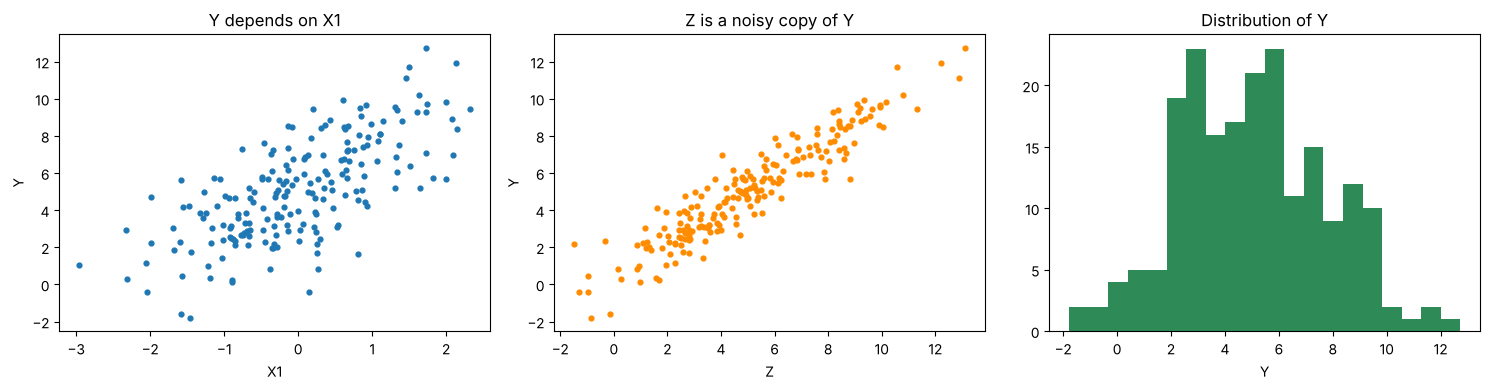

In [7]:
# ===== Step 2e — Look at the data =====
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].scatter(full["X1"], full["Y"], s=12)
axes[0].set_xlabel("X1"); axes[0].set_ylabel("Y"); axes[0].set_title("Y depends on X1")

axes[1].scatter(full["Z"], full["Y"], s=12, color="darkorange")
axes[1].set_xlabel("Z"); axes[1].set_ylabel("Y"); axes[1].set_title("Z is a noisy copy of Y")

axes[2].hist(full["Y"], bins=20, color="seagreen")
axes[2].set_xlabel("Y"); axes[2].set_title("Distribution of Y")

plt.tight_layout()
plt.show()

## 3. The analysis model

Every method ends in the same regression of **Y on X1, X2, X3**. The helper below returns the coefficients and their standard errors, both ordered `[intercept, X1, X2, X3]`.

In [8]:
# ===== Step 3a — The regression helper =====
def ols(d):
    """Least squares of Y on X1, X2, X3. Returns (coefficients, standard errors).
    The rows must have no missing values."""
    A = np.column_stack([np.ones(len(d)), d[["X1", "X2", "X3"]].to_numpy()])
    y = d["Y"].to_numpy()
    AtA_inv = np.linalg.inv(A.T @ A)
    beta = AtA_inv @ A.T @ y
    resid = y - A @ beta
    sigma2 = resid @ resid / (len(y) - A.shape[1])
    return beta, np.sqrt(sigma2 * np.diag(AtA_inv))

In [9]:
# ===== Step 3b — Check the helper against statsmodels =====
sm_fit = sm.OLS(full["Y"], sm.add_constant(full[["X1", "X2", "X3"]])).fit()
beta_check, se_check = ols(full)
print("ols() matches statsmodels:", np.allclose(beta_check, sm_fit.params) and np.allclose(se_check, sm_fit.bse))
print()
print(sm_fit.summary().tables[1])

ols() matches statsmodels: True

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.9629      0.073     68.376      0.000       4.820       5.106
X1             2.0368      0.072     28.216      0.000       1.894       2.179
X2            -1.5076      0.075    -20.129      0.000      -1.655      -1.360
X3             0.9483      0.078     12.217      0.000       0.795       1.101


In [10]:
# ===== Step 3c — Baseline: the regression on the complete data (nothing missing) =====
beta_full, se_full = ols(full)

baseline = pd.DataFrame({"true value": TRUE_BETA, "full-data estimate": beta_full, "SE": se_full},
                        index=["intercept", "X1", "X2", "X3"])
display(baseline.round(3))
print(f"Full-data estimate of beta1: {beta_full[1]:.3f}   (true value 2)")
print("This is the best any method can hope to match: it is what we would get if nothing were missing.")

,true value,full-data estimate,SE
intercept,5.0,4.963,0.073
X1,2.0,2.037,0.072
X2,-1.5,-1.508,0.075
X3,1.0,0.948,0.078


Full-data estimate of beta1: 2.037   (true value 2)
This is the best any method can hope to match: it is what we would get if nothing were missing.


## 4. Creating the missing data

About **20% of the values of Y and of X1** are deleted. The chance that a value is deleted depends on the mechanism:

* **MCAR** (missing completely at random) – 20% for everyone, pure luck.
* **MAR** (missing at random) – depends on **Z**, which is always observed. Because Z is related to Y, complete-case analysis is distorted, but methods that use Z can correct for it.
* **MNAR** (missing not at random) – depends on the **value itself** (large Y and large X1 are more likely to vanish). Nothing in the observed data reveals this, so no method can fully repair it.

For MAR and MNAR the chance is `expit(−2.23 + 2 × standardised driver)`; the intercept is tuned so that about 20% goes missing in every mechanism.

In [11]:
# ===== Step 4a — Helper, and the MCAR deletion rule =====
def standardize(s):
    """Rescale to mean 0 and standard deviation 1."""
    return (s - s.mean()) / s.std()


def delete_mcar(full, rng):
    """MCAR: every value of Y and X1 has the same 20% chance of being deleted."""
    data = full.copy()
    for col in ["Y", "X1"]:
        data.loc[rng.random(len(full)) < 0.20, col] = np.nan
    return data

In [12]:
# ===== Step 4b — The MAR deletion rule =====
def delete_mar(full, rng):
    """MAR: the chance of deletion depends on Z, which is always observed."""
    data = full.copy()
    prob = expit(-2.23 + 2.0 * standardize(full["Z"]))          # larger Z -> more likely to be deleted
    for col in ["Y", "X1"]:
        data.loc[rng.random(len(full)) < prob, col] = np.nan
    return data

In [13]:
# ===== Step 4c — The MNAR deletion rule =====
def delete_mnar(full, rng):
    """MNAR: the chance of deletion depends on the very value that gets deleted."""
    data = full.copy()
    for col in ["Y", "X1"]:
        prob = expit(-2.23 + 2.0 * standardize(full[col]))      # larger value -> more likely to be deleted
        data.loc[rng.random(len(full)) < prob, col] = np.nan
    return data

In [14]:
# ===== Step 4d — One function that applies any of the three rules =====
def make_missing(full, mechanism, rng):
    rules = {"MCAR": delete_mcar, "MAR": delete_mar, "MNAR": delete_mnar}
    return rules[mechanism](full, rng)

In [15]:
# ===== Step 4e — Create the MCAR dataset =====
rng = np.random.default_rng(SEED)
df_mcar = make_missing(full, "MCAR", rng)

print("Missing values per column:")
print(df_mcar.isna().sum().to_string())
print(f"\nRows with at least one gap: {df_mcar.isna().any(axis=1).sum()} of {len(df_mcar)}")
df_mcar.head(8)

Missing values per column:
X1    45
X2     0
X3     0
Z      0
Y     43

Rows with at least one gap: 78 of 200


,X1,X2,X3,Z,Y
0,0.304717,-1.039984,0.750451,7.590227,8.435272
1,0.940565,-1.951035,-1.302180,6.844265,7.927964
2,0.127840,-0.316243,-0.016801,7.332296,6.987691
3,NaN,0.879398,0.777792,2.504300,2.125020
4,NaN,1.127241,0.467509,4.559425,NaN
5,-0.859292,0.368751,-0.958883,3.410518,2.310538
6,NaN,-0.049926,-0.184862,7.277625,7.409854
7,-0.680930,1.222541,-0.154529,0.853693,2.097899


In [16]:
# ===== Step 4f — Create the MAR dataset =====
rng = np.random.default_rng(SEED)
df_mar = make_missing(full, "MAR", rng)

print("Missing values per column:")
print(df_mar.isna().sum().to_string())
print(f"\nRows with at least one gap: {df_mar.isna().any(axis=1).sum()} of {len(df_mar)}")
df_mar.head(8)

Missing values per column:
X1    39
X2     0
X3     0
Z      0
Y     40

Rows with at least one gap: 61 of 200


,X1,X2,X3,Z,Y
0,0.304717,-1.039984,0.750451,7.590227,8.435272
1,0.940565,-1.951035,-1.302180,6.844265,7.927964
2,0.127840,-0.316243,-0.016801,7.332296,6.987691
3,-0.853044,0.879398,0.777792,2.504300,2.125020
4,NaN,1.127241,0.467509,4.559425,3.272094
5,-0.859292,0.368751,-0.958883,3.410518,2.310538
6,NaN,-0.049926,-0.184862,7.277625,7.409854
7,-0.680930,1.222541,-0.154529,0.853693,2.097899


In [17]:
# ===== Step 4g — Create the MNAR dataset =====
rng = np.random.default_rng(SEED)
df_mnar = make_missing(full, "MNAR", rng)

print("Missing values per column:")
print(df_mnar.isna().sum().to_string())
print(f"\nRows with at least one gap: {df_mnar.isna().any(axis=1).sum()} of {len(df_mnar)}")
df_mnar.head(8)

Missing values per column:
X1    41
X2     0
X3     0
Z      0
Y     41

Rows with at least one gap: 65 of 200


,X1,X2,X3,Z,Y
0,0.304717,-1.039984,0.750451,7.590227,8.435272
1,0.940565,-1.951035,-1.302180,6.844265,NaN
2,0.127840,-0.316243,-0.016801,7.332296,6.987691
3,-0.853044,0.879398,0.777792,2.504300,2.125020
4,NaN,1.127241,0.467509,4.559425,3.272094
5,-0.859292,0.368751,-0.958883,3.410518,2.310538
6,NaN,-0.049926,-0.184862,7.277625,7.409854
7,-0.680930,1.222541,-0.154529,0.853693,2.097899


In [18]:
# ===== Step 4h — Collect the three datasets and compare how much is missing =====
datasets = {"MCAR": df_mcar, "MAR": df_mar, "MNAR": df_mnar}

missing_counts = pd.DataFrame({mech: d.isna().sum() for mech, d in datasets.items()})
missing_counts.loc["rows with any gap"] = [d.isna().any(axis=1).sum() for d in datasets.values()]
missing_counts

,MCAR,MAR,MNAR
X1,45,39,41
X2,0,0,0
X3,0,0,0
Z,0,0,0
Y,43,40,41
rows with any gap,78,61,65


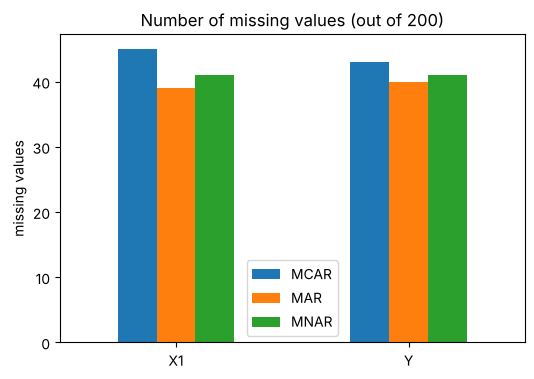

In [19]:
# ===== Step 4i — Bar chart of the missing counts =====
missing_counts.loc[["X1", "Y"]].plot.bar(figsize=(6, 4), rot=0)
plt.title("Number of missing values (out of %d)" % N)
plt.ylabel("missing values")
plt.show()

In [20]:
# ===== Step 4j — Check that the three mechanisms behave as designed =====
# Done on a very large dataset so that the pattern is not hidden by noise.
big = make_data(np.random.default_rng(1), n=20_000)

rows = []
for mech in MECHANISMS:
    d = make_missing(big, mech, np.random.default_rng(2))
    gone = d["Y"].isna()
    rows.append({
        "Mechanism": mech,
        "Y missing %": 100 * gone.mean(),
        "X1 missing %": 100 * d["X1"].isna().mean(),
        "Rows with any gap %": 100 * d.isna().any(axis=1).mean(),
        "Z gap": big["Z"][gone].mean() - big["Z"][~gone].mean(),
        "Y gap": big["Y"][gone].mean() - big["Y"][~gone].mean(),
    })
pd.DataFrame(rows).set_index("Mechanism").round(2)

,Y missing %,X1 missing %,Rows with any gap %,Z gap,Y gap
Mechanism,,,,,
MCAR,20.11,20.02,36.10,-0.01,-0.03
MAR,19.87,20.16,30.58,3.96,3.53
MNAR,19.82,20.08,32.28,3.74,3.72


*Gap* = average value among rows where Y went missing minus the average among the others. Under MCAR both gaps are about zero. Under MAR and MNAR, rows with a missing Y have higher Z and higher Y. (We can only see the Y gap because we deleted the values ourselves; in real data it is invisible — which is why MAR and MNAR cannot be told apart from the observed data alone.)

# 5. The eight methods, step by step (one dataset)

One complete dataset (`full`, seed 42) has been damaged three ways (`df_mcar`, `df_mar`, `df_mnar`). In this section every method is applied to each of them, so that we can **see** what each method does to the data and to the estimate.

> This section is an **illustration**. One dataset is one random draw, so no conclusions about which method is better are drawn here — those come from the Monte Carlo study in Section 7.

Every method gets its own section with the same steps:

* **a – define** the method as a small function
* **b, c, d – apply** it to the MCAR, MAR and MNAR datasets and look at what it did

## 5.1 Helpers for the walkthrough

In [21]:
# ===== Step 5.1a — Where the walkthrough keeps its results =====
estimates = {}    # estimates[(method, mechanism)] = (coefficients, "naive" standard errors)
intervals = {}    # intervals[(method, mechanism)] = (SE of beta1, CI lower, CI upper)  (MICE only, Rubin's rules)


def show_estimate(method, mech):
    beta, se = estimates[(method, mech)]
    se_text = "n/a" if se is None else f"{se[1]:.3f}"
    print(f"{method} | {mech}:  beta1 = {beta[1]:.3f}   formula SE = {se_text}   "
          f"(difference from the full-data fit: {beta[1] - beta_full[1]:+.3f})")


def show_interval(method, mech):
    se, low, high = intervals[(method, mech)]
    print(f"{method} | {mech}:  Rubin SE = {se:.3f}   95% CI = ({low:.3f}, {high:.3f})")

In [22]:
# ===== Step 5.1b — Peek at what a method filled in =====
def peek(data, filled, truth, col="Y", n=5):
    """The first n deleted values of `col`: the true value next to what the method filled in."""
    gone = data[col].isna()
    table = pd.DataFrame({"true value": truth.loc[gone, col], "filled in": filled.loc[gone, col]})
    return table.head(n).round(2)

## 5.2 Method 1 — Complete case

**Idea:** delete every row that has any gap, then run the regression on what is left.

**Good:** simple, and unbiased when the data are MCAR. **Bad:** it throws away information (about a third of the rows here), and it is biased when missingness is related to the outcome (MAR through Z, and MNAR).

**Intervals in the Monte Carlo study:** the classical interval (valid for the rows that are kept) and the two bootstrap intervals (Section 6).

In [23]:
# ===== Step 5.2a — Complete case: the method =====
def drop_incomplete(data, rng):
    """Remove every row that has at least one missing value."""
    return data.dropna()


def complete_case(data, rng):
    """Complete-case analysis = drop the incomplete rows, then run the regression."""
    return ols(drop_incomplete(data, rng))

In [24]:
# ===== Step 5.2b — Complete case: MCAR dataset =====
rng = np.random.default_rng(SEED)

kept = drop_incomplete(df_mcar, rng)                                  # 1. throw away the incomplete rows
print(f"Rows kept: {len(kept)} of {len(df_mcar)}  ({len(df_mcar) - len(kept)} rows discarded)")

estimates[("Complete Case", "MCAR")] = ols(kept)                 # 2. regression on the remaining rows
show_estimate("Complete Case", "MCAR")

Rows kept: 122 of 200  (78 rows discarded)
Complete Case | MCAR:  beta1 = 2.098   formula SE = 0.092   (difference from the full-data fit: +0.061)


In [25]:
# ===== Step 5.2c — Complete case: MAR dataset =====
rng = np.random.default_rng(SEED)

kept = drop_incomplete(df_mar, rng)                                  # 1. throw away the incomplete rows
print(f"Rows kept: {len(kept)} of {len(df_mar)}  ({len(df_mar) - len(kept)} rows discarded)")

estimates[("Complete Case", "MAR")] = ols(kept)                 # 2. regression on the remaining rows
show_estimate("Complete Case", "MAR")

Rows kept: 139 of 200  (61 rows discarded)
Complete Case | MAR:  beta1 = 1.844   formula SE = 0.105   (difference from the full-data fit: -0.193)


In [26]:
# ===== Step 5.2d — Complete case: MNAR dataset =====
rng = np.random.default_rng(SEED)

kept = drop_incomplete(df_mnar, rng)                                  # 1. throw away the incomplete rows
print(f"Rows kept: {len(kept)} of {len(df_mnar)}  ({len(df_mnar) - len(kept)} rows discarded)")

estimates[("Complete Case", "MNAR")] = ols(kept)                 # 2. regression on the remaining rows
show_estimate("Complete Case", "MNAR")

Rows kept: 135 of 200  (65 rows discarded)
Complete Case | MNAR:  beta1 = 2.015   formula SE = 0.115   (difference from the full-data fit: -0.022)


## 5.3 Method 2 — Mean imputation

**Idea:** replace every gap by the mean of the observed values in that column.

**Problem:** every filled-in value sits exactly at the mean, so the variation in Y and X1 shrinks and the relationship between them weakens (the slope is pulled towards zero). The filled-in values are also treated as real data, so the standard error is too small.

**Intervals in the Monte Carlo study:** the classical interval (here it is *naive*, because it treats the filled-in values as real) and the two bootstrap intervals (Section 6).

In [27]:
# ===== Step 5.3a — Mean imputation: the method =====
def fill_mean(data, rng):
    """Replace every gap by the mean of the observed values in that column."""
    return data.fillna(data.mean())                  # data.mean() skips the gaps


def mean_imputation(data, rng):
    return ols(fill_mean(data, rng))

In [28]:
# ===== Step 5.3b — Mean imputation: MCAR dataset =====
rng = np.random.default_rng(SEED)

print("Means used to fill the gaps:")
print(df_mcar[["X1", "Y"]].mean().round(2).to_string())

filled = fill_mean(df_mcar, rng)                                      # 1. fill every gap with its column mean
print(f"\nCells filled in: {df_mcar.isna().sum().sum()}.  True Y vs what was filled in:")
display(peek(df_mcar, filled, full))

estimates[("Mean Imputation", "MCAR")] = ols(filled)             # 2. regression on the completed data
show_estimate("Mean Imputation", "MCAR")

Means used to fill the gaps:
X1   -0.03
Y     5.10

Cells filled in: 88.  True Y vs what was filled in:


,true value,filled in
4,3.27,5.1
8,3.52,5.1
17,8.37,5.1
25,6.65,5.1
27,5.20,5.1


Mean Imputation | MCAR:  beta1 = 1.622   formula SE = 0.126   (difference from the full-data fit: -0.415)


In [29]:
# ===== Step 5.3c — Mean imputation: MAR dataset =====
rng = np.random.default_rng(SEED)

print("Means used to fill the gaps:")
print(df_mar[["X1", "Y"]].mean().round(2).to_string())

filled = fill_mean(df_mar, rng)                                      # 1. fill every gap with its column mean
print(f"\nCells filled in: {df_mar.isna().sum().sum()}.  True Y vs what was filled in:")
display(peek(df_mar, filled, full))

estimates[("Mean Imputation", "MAR")] = ols(filled)             # 2. regression on the completed data
show_estimate("Mean Imputation", "MAR")

Means used to fill the gaps:
X1   -0.22
Y     4.35

Cells filled in: 79.  True Y vs what was filled in:


,true value,filled in
10,8.35,4.35
17,8.37,4.35
19,11.71,4.35
25,6.65,4.35
27,5.20,4.35


Mean Imputation | MAR:  beta1 = 1.346   formula SE = 0.133   (difference from the full-data fit: -0.691)


In [30]:
# ===== Step 5.3d — Mean imputation: MNAR dataset =====
rng = np.random.default_rng(SEED)

print("Means used to fill the gaps:")
print(df_mnar[["X1", "Y"]].mean().round(2).to_string())

filled = fill_mean(df_mnar, rng)                                      # 1. fill every gap with its column mean
print(f"\nCells filled in: {df_mnar.isna().sum().sum()}.  True Y vs what was filled in:")
display(peek(df_mnar, filled, full))

estimates[("Mean Imputation", "MNAR")] = ols(filled)             # 2. regression on the completed data
show_estimate("Mean Imputation", "MNAR")

Means used to fill the gaps:
X1   -0.29
Y     4.30

Cells filled in: 82.  True Y vs what was filled in:


,true value,filled in
1,7.93,4.3
10,8.35,4.3
17,8.37,4.3
19,11.71,4.3
25,6.65,4.3


Mean Imputation | MNAR:  beta1 = 1.263   formula SE = 0.151   (difference from the full-data fit: -0.774)


## 5.4 Method 3 — Hot-deck

**Idea:** for every row with a gap, find the most *similar* row (the nearest neighbour on the other variables, after standardising them) and copy its value. The filled-in values are real observed values, so their distribution looks realistic.

**Problem:** each gap gets only one donor, and the result is treated as real data, so the standard error is still too small.

**Intervals in the Monte Carlo study:** the classical interval (here it is *naive*, because it treats the filled-in values as real) and the two bootstrap intervals (Section 6).

In [31]:
# ===== Step 5.4a — Hot-deck: the method =====
def fill_hot_deck(data, rng):
    """Copy every missing value from the most similar row (one nearest neighbour)."""
    mean, sd = data.mean(), data.std()
    standardised = (data - mean) / sd                                      # put all variables on the same scale
    filled = KNNImputer(n_neighbors=1).fit_transform(standardised)         # 1 neighbour = 1 donor
    return pd.DataFrame(filled, columns=data.columns) * sd + mean          # back to the original scale


def hot_deck(data, rng):
    return ols(fill_hot_deck(data, rng))

In [32]:
# ===== Step 5.4b — Hot-deck: MCAR dataset =====
rng = np.random.default_rng(SEED)

filled = fill_hot_deck(df_mcar, rng)                                  # 1. copy values from the nearest rows
print(f"Cells filled in: {df_mcar.isna().sum().sum()}.  True Y vs what was filled in:")
display(peek(df_mcar, filled, full))

estimates[("Hot-Deck", "MCAR")] = ols(filled)                    # 2. regression on the completed data
show_estimate("Hot-Deck", "MCAR")

Cells filled in: 88.  True Y vs what was filled in:


,true value,filled in
4,3.27,5.35
8,3.52,2.87
17,8.37,7.35
25,6.65,6.76
27,5.20,4.13


Hot-Deck | MCAR:  beta1 = 2.005   formula SE = 0.082   (difference from the full-data fit: -0.032)


In [33]:
# ===== Step 5.4c — Hot-deck: MAR dataset =====
rng = np.random.default_rng(SEED)

filled = fill_hot_deck(df_mar, rng)                                  # 1. copy values from the nearest rows
print(f"Cells filled in: {df_mar.isna().sum().sum()}.  True Y vs what was filled in:")
display(peek(df_mar, filled, full))

estimates[("Hot-Deck", "MAR")] = ols(filled)                    # 2. regression on the completed data
show_estimate("Hot-Deck", "MAR")

Cells filled in: 79.  True Y vs what was filled in:


,true value,filled in
10,8.35,7.67
17,8.37,7.35
19,11.71,9.05
25,6.65,6.76
27,5.20,4.13


Hot-Deck | MAR:  beta1 = 1.878   formula SE = 0.084   (difference from the full-data fit: -0.159)


In [34]:
# ===== Step 5.4d — Hot-deck: MNAR dataset =====
rng = np.random.default_rng(SEED)

filled = fill_hot_deck(df_mnar, rng)                                  # 1. copy values from the nearest rows
print(f"Cells filled in: {df_mnar.isna().sum().sum()}.  True Y vs what was filled in:")
display(peek(df_mnar, filled, full))

estimates[("Hot-Deck", "MNAR")] = ols(filled)                    # 2. regression on the completed data
show_estimate("Hot-Deck", "MNAR")

Cells filled in: 82.  True Y vs what was filled in:


,true value,filled in
1,7.93,8.80
10,8.35,7.67
17,8.37,7.35
19,11.71,9.05
25,6.65,6.76


Hot-Deck | MNAR:  beta1 = 1.935   formula SE = 0.111   (difference from the full-data fit: -0.102)


## 5.5 The imputation engine (used by methods 4–7)

Regression imputation, stochastic regression and both MICE versions share one engine. It **regresses each incomplete variable on all the other variables (including Z)** and cycles through the incomplete variables a few times. The methods differ only in what is put into the gaps — and each step adds one ingredient:

1. `"regression"` — the predicted value (no noise, so the filled-in data look too tidy).
2. `"stochastic"` — the predicted value plus a randomly chosen residual (restores the natural spread).
3. `"normal"` and `"pmm"` — the **MICE** versions. They first draw *new regression coefficients* (so the uncertainty about the model is reflected too) and are repeated several times. `"normal"` draws the value from the regression model; `"pmm"` (predictive mean matching) borrows the real observed value of one of the 5 rows whose predicted value is closest.

The engine is built from four small functions.

In [35]:
# ===== Step 5.5a — Fit the regression for one incomplete column =====
def regress_column(X, holes, j):
    """Regress column j on all the other columns, using only the rows where column j is observed."""
    obs, mis = ~holes[:, j], holes[:, j]
    A = np.column_stack([np.ones(len(X)), np.delete(X, j, axis=1)])        # predictors = all other columns
    beta, *_ = np.linalg.lstsq(A[obs], X[obs, j], rcond=None)
    resid = X[obs, j] - A[obs] @ beta
    return A, beta, resid, obs, mis

In [36]:
# ===== Step 5.5b — MICE ingredient: draw new coefficients =====
def draw_new_coefficients(A, obs, beta, resid, rng):
    """Instead of treating the fitted coefficients as exact, draw new ones from their uncertainty."""
    df_res = obs.sum() - A.shape[1]
    sigma2 = resid @ resid / rng.chisquare(df_res)                                        # new error variance
    beta_new = rng.multivariate_normal(beta, sigma2 * np.linalg.inv(A[obs].T @ A[obs]))   # new coefficients
    return beta_new, sigma2

In [37]:
# ===== Step 5.5c — MICE ingredient: predictive mean matching =====
def pmm_donors(pred_obs, pred_mis, y_obs, rng, k=5):
    """For every gap, find the k observed rows whose predicted value is closest,
    pick one of them at random and copy its REAL observed value."""
    nearest = np.argsort(np.abs(pred_mis[:, None] - pred_obs[None, :]), axis=1)[:, :k]
    chosen = nearest[np.arange(len(pred_mis)), rng.integers(0, k, len(pred_mis))]
    return y_obs[chosen]

In [38]:
# ===== Step 5.5d — The engine itself =====
def chained_impute(data, kind, rng, cycles=5):
    """Fill the gaps one variable at a time, cycling through the incomplete variables.
    kind = "regression" | "stochastic" | "normal" | "pmm"."""
    X = data.to_numpy().copy()
    holes = np.isnan(X)
    X = np.where(holes, np.nanmean(X, axis=0), X)                      # start with simple mean imputation

    for _ in range(cycles):
        for j in np.where(holes.any(axis=0))[0]:                       # each incomplete variable in turn
            A, beta, resid, obs, mis = regress_column(X, holes, j)

            if kind == "regression":                                   # the predicted value
                X[mis, j] = A[mis] @ beta
            elif kind == "stochastic":                                 # predicted value + a random residual
                X[mis, j] = A[mis] @ beta + rng.choice(resid, mis.sum())
            else:                                                      # MICE: first draw new coefficients
                beta_new, sigma2 = draw_new_coefficients(A, obs, beta, resid, rng)
                if kind == "normal":                                   # a draw from the regression model
                    X[mis, j] = A[mis] @ beta_new + rng.normal(0, np.sqrt(sigma2), mis.sum())
                else:                                                  # "pmm": a real value from a similar row
                    X[mis, j] = pmm_donors(A[obs] @ beta, A[mis] @ beta_new, X[obs, j], rng)

    return pd.DataFrame(X, columns=data.columns)

## 5.6 Method 4 — Regression imputation

**Idea:** fill each gap with its predicted value from a regression on all the other variables (Z included).

**Problem:** the filled-in values lie *exactly* on the regression line, so there is no scatter around it. Relationships look stronger than they really are, and the data look more certain than they are.

**Intervals in the Monte Carlo study:** the classical interval (here it is *naive*, because it treats the filled-in values as real) and the two bootstrap intervals (Section 6).

In [39]:
# ===== Step 5.6a — Regression imputation: the method =====
def fill_regression(data, rng):
    return chained_impute(data, "regression", rng)


def regression_imputation(data, rng):
    return ols(fill_regression(data, rng))

In [40]:
# ===== Step 5.6b — Regression imputation: MCAR dataset =====
rng = np.random.default_rng(SEED)

filled = fill_regression(df_mcar, rng)                                # 1. fill every gap with its predicted value
print(f"Cells filled in: {df_mcar.isna().sum().sum()}.  True Y vs what was filled in:")
display(peek(df_mcar, filled, full))

estimates[("Regression Imputation", "MCAR")] = ols(filled)       # 2. regression on the completed data
show_estimate("Regression Imputation", "MCAR")

Cells filled in: 88.  True Y vs what was filled in:


,true value,filled in
4,3.27,4.49
8,3.52,3.74
17,8.37,8.31
25,6.65,7.04
27,5.20,4.35


Regression Imputation | MCAR:  beta1 = 2.168   formula SE = 0.060   (difference from the full-data fit: +0.131)


In [41]:
# ===== Step 5.6c — Regression imputation: MAR dataset =====
rng = np.random.default_rng(SEED)

filled = fill_regression(df_mar, rng)                                # 1. fill every gap with its predicted value
print(f"Cells filled in: {df_mar.isna().sum().sum()}.  True Y vs what was filled in:")
display(peek(df_mar, filled, full))

estimates[("Regression Imputation", "MAR")] = ols(filled)       # 2. regression on the completed data
show_estimate("Regression Imputation", "MAR")

Cells filled in: 79.  True Y vs what was filled in:


,true value,filled in
10,8.35,8.75
17,8.37,8.23
19,11.71,10.01
25,6.65,6.93
27,5.20,4.41


Regression Imputation | MAR:  beta1 = 2.110   formula SE = 0.068   (difference from the full-data fit: +0.074)


In [42]:
# ===== Step 5.6d — Regression imputation: MNAR dataset =====
rng = np.random.default_rng(SEED)

filled = fill_regression(df_mnar, rng)                                # 1. fill every gap with its predicted value
print(f"Cells filled in: {df_mnar.isna().sum().sum()}.  True Y vs what was filled in:")
display(peek(df_mnar, filled, full))

estimates[("Regression Imputation", "MNAR")] = ols(filled)       # 2. regression on the completed data
show_estimate("Regression Imputation", "MNAR")

Cells filled in: 82.  True Y vs what was filled in:


,true value,filled in
1,7.93,7.64
10,8.35,7.46
17,8.37,8.15
19,11.71,9.94
25,6.65,7.01


Regression Imputation | MNAR:  beta1 = 2.212   formula SE = 0.071   (difference from the full-data fit: +0.175)


## 5.7 Method 5 — Stochastic regression

**Idea:** like regression imputation, but a randomly chosen residual is added to each predicted value, which restores the natural scatter around the regression line.

**Problem:** it is still a *single* imputation, so the uncertainty about the filled-in values is ignored by the naive standard error.

**Intervals in the Monte Carlo study:** the classical interval (here it is *naive*, because it treats the filled-in values as real) and the two bootstrap intervals (Section 6).

In [43]:
# ===== Step 5.7a — Stochastic regression: the method =====
def fill_stochastic(data, rng):
    return chained_impute(data, "stochastic", rng)


def stochastic_regression(data, rng):
    return ols(fill_stochastic(data, rng))

In [44]:
# ===== Step 5.7b — Stochastic regression: MCAR dataset =====
rng = np.random.default_rng(SEED)

filled = fill_stochastic(df_mcar, rng)                                # 1. predicted value + random residual
print(f"Cells filled in: {df_mcar.isna().sum().sum()}.  True Y vs what was filled in:")
display(peek(df_mcar, filled, full))

estimates[("Stochastic Regression", "MCAR")] = ols(filled)       # 2. regression on the completed data
show_estimate("Stochastic Regression", "MCAR")

Cells filled in: 88.  True Y vs what was filled in:


,true value,filled in
4,3.27,3.93
8,3.52,2.50
17,8.37,9.14
25,6.65,6.71
27,5.20,4.20


Stochastic Regression | MCAR:  beta1 = 2.060   formula SE = 0.069   (difference from the full-data fit: +0.023)


In [45]:
# ===== Step 5.7c — Stochastic regression: MAR dataset =====
rng = np.random.default_rng(SEED)

filled = fill_stochastic(df_mar, rng)                                # 1. predicted value + random residual
print(f"Cells filled in: {df_mar.isna().sum().sum()}.  True Y vs what was filled in:")
display(peek(df_mar, filled, full))

estimates[("Stochastic Regression", "MAR")] = ols(filled)       # 2. regression on the completed data
show_estimate("Stochastic Regression", "MAR")

Cells filled in: 79.  True Y vs what was filled in:


,true value,filled in
10,8.35,9.18
17,8.37,8.54
19,11.71,10.75
25,6.65,6.06
27,5.20,5.81


Stochastic Regression | MAR:  beta1 = 2.085   formula SE = 0.079   (difference from the full-data fit: +0.048)


In [46]:
# ===== Step 5.7d — Stochastic regression: MNAR dataset =====
rng = np.random.default_rng(SEED)

filled = fill_stochastic(df_mnar, rng)                                # 1. predicted value + random residual
print(f"Cells filled in: {df_mnar.isna().sum().sum()}.  True Y vs what was filled in:")
display(peek(df_mnar, filled, full))

estimates[("Stochastic Regression", "MNAR")] = ols(filled)       # 2. regression on the completed data
show_estimate("Stochastic Regression", "MNAR")

Cells filled in: 82.  True Y vs what was filled in:


,true value,filled in
1,7.93,9.09
10,8.35,8.50
17,8.37,7.91
19,11.71,10.43
25,6.65,8.14


Stochastic Regression | MNAR:  beta1 = 2.120   formula SE = 0.079   (difference from the full-data fit: +0.084)


## 5.8 Methods 6 and 7 — MICE (normal) and MICE (PMM)

**MICE = Multiple Imputation by Chained Equations.** Instead of filling the gaps once, we do it **m times** (`M_IMPUTATIONS`), each time with newly drawn coefficients and new random values. That gives m *different* completed datasets:

1. **Impute** m times.
2. **Fit** the regression on each completed dataset.
3. **Pool** the results with **Rubin's rules**:  
   β̂ = average of the m estimates  
   total variance = *within* + (1 + 1/m) × *between*  
   where *within* is the average sampling variance and *between* is how much the m estimates disagree. The *between* part is what captures the uncertainty caused by the missing data — single imputation has none.

The two versions differ only in the imputation step: **normal** draws values from the regression model, **PMM** borrows real observed values from similar rows. No bootstrap is needed: Rubin's rules give the standard error and the interval directly (the **Rubin interval**).

In [47]:
# ===== Step 5.8a — MICE, step 1: create m completed datasets =====
def mice_impute(data, kind, rng):
    return [chained_impute(data, kind, rng) for _ in range(M_IMPUTATIONS)]

In [48]:
# ===== Step 5.8b — MICE, step 2: fit the regression on every completed dataset =====
def fit_each(completed):
    """Returns the coefficients and the sampling variances, one row per completed dataset."""
    fits = [ols(d) for d in completed]
    return np.array([f[0] for f in fits]), np.array([f[1] ** 2 for f in fits])

In [49]:
# ===== Step 5.8c — MICE, step 3: pool with Rubin's rules =====
def pool_rubin(betas, variances):
    m = len(betas)
    within = variances.mean(axis=0)                     # average sampling variance
    between = betas.var(axis=0, ddof=1)                 # disagreement between the m completed datasets
    total = within + (1 + 1 / m) * between
    return betas.mean(axis=0), np.sqrt(total), within, between

In [50]:
# ===== Step 5.8d — The two MICE methods as one-line functions =====
def mice_normal(data, rng):
    betas, variances = fit_each(mice_impute(data, "normal", rng))
    beta, se, _, _ = pool_rubin(betas, variances)
    return beta, se


def mice_pmm(data, rng):
    betas, variances = fit_each(mice_impute(data, "pmm", rng))
    beta, se, _, _ = pool_rubin(betas, variances)
    return beta, se


def peek_many(data, completed, truth, col="Y", n=5, shown=3):
    """True values of the first deleted entries of `col`, next to what the first few imputations filled in."""
    gone = data[col].isna()
    table = pd.DataFrame({"true value": truth.loc[gone, col]})
    for k in range(shown):
        table[f"imputation {k + 1}"] = completed[k].loc[gone, col]
    return table.head(n).round(2)

### MICE (normal)

In [51]:
# ===== Step 5.8e — MICE (normal): MCAR dataset =====
rng = np.random.default_rng(SEED)

completed = mice_impute(df_mcar, "normal", rng)                       # 1. m completed datasets
print("True Y vs what the first three imputations filled in (note: they differ!):")
display(peek_many(df_mcar, completed, full))

betas, variances = fit_each(completed)                               # 2. regression on each
per_imputation = pd.DataFrame({"beta1": betas[:, 1], "SE": np.sqrt(variances[:, 1])},
                              index=[f"imputation {k + 1}" for k in range(len(betas))])
display(per_imputation.round(3))

beta, se, within, between = pool_rubin(betas, variances)             # 3. Rubin's rules
print(f"within-variance = {within[1]:.5f}   between-variance = {between[1]:.5f}")
estimates[("MICE (normal)", "MCAR")] = (beta, se)
intervals[("MICE (normal)", "MCAR")] = (se[1], beta[1] - 1.96 * se[1], beta[1] + 1.96 * se[1])
show_estimate("MICE (normal)", "MCAR")
show_interval("MICE (normal)", "MCAR")

True Y vs what the first three imputations filled in (note: they differ!):


,true value,imputation 1,imputation 2,imputation 3
4,3.27,7.10,3.48,3.45
8,3.52,4.37,2.56,3.75
17,8.37,6.73,8.16,8.42
25,6.65,7.27,7.32,6.57
27,5.20,3.98,3.45,4.48


,beta1,SE
imputation 1,2.097,0.076
imputation 2,2.089,0.071
imputation 3,2.101,0.077
imputation 4,2.083,0.072
imputation 5,2.035,0.070
imputation 6,2.076,0.072
imputation 7,2.162,0.072
imputation 8,2.087,0.069
imputation 9,2.031,0.066
imputation 10,2.055,0.070


within-variance = 0.00511   between-variance = 0.00140
MICE (normal) | MCAR:  beta1 = 2.082   formula SE = 0.082   (difference from the full-data fit: +0.045)
MICE (normal) | MCAR:  Rubin SE = 0.082   95% CI = (1.922, 2.241)


In [52]:
# ===== Step 5.8f — MICE (normal): MAR dataset =====
rng = np.random.default_rng(SEED)

completed = mice_impute(df_mar, "normal", rng)                       # 1. m completed datasets
print("True Y vs what the first three imputations filled in (note: they differ!):")
display(peek_many(df_mar, completed, full))

betas, variances = fit_each(completed)                               # 2. regression on each
per_imputation = pd.DataFrame({"beta1": betas[:, 1], "SE": np.sqrt(variances[:, 1])},
                              index=[f"imputation {k + 1}" for k in range(len(betas))])
display(per_imputation.round(3))

beta, se, within, between = pool_rubin(betas, variances)             # 3. Rubin's rules
print(f"within-variance = {within[1]:.5f}   between-variance = {between[1]:.5f}")
estimates[("MICE (normal)", "MAR")] = (beta, se)
intervals[("MICE (normal)", "MAR")] = (se[1], beta[1] - 1.96 * se[1], beta[1] + 1.96 * se[1])
show_estimate("MICE (normal)", "MAR")
show_interval("MICE (normal)", "MAR")

True Y vs what the first three imputations filled in (note: they differ!):


,true value,imputation 1,imputation 2,imputation 3
10,8.35,7.35,7.03,7.83
17,8.37,6.61,7.26,7.99
19,11.71,9.03,12.14,10.72
25,6.65,7.41,6.53,7.21
27,5.20,5.76,4.01,4.21


,beta1,SE
imputation 1,1.948,0.073
imputation 2,2.014,0.072
imputation 3,2.012,0.075
imputation 4,2.073,0.084
imputation 5,2.093,0.085
imputation 6,2.081,0.078
imputation 7,2.102,0.077
imputation 8,2.048,0.076
imputation 9,2.055,0.070
imputation 10,1.930,0.074


within-variance = 0.00583   between-variance = 0.00349
MICE (normal) | MAR:  beta1 = 2.036   formula SE = 0.098   (difference from the full-data fit: -0.001)
MICE (normal) | MAR:  Rubin SE = 0.098   95% CI = (1.843, 2.228)


In [53]:
# ===== Step 5.8g — MICE (normal): MNAR dataset =====
rng = np.random.default_rng(SEED)

completed = mice_impute(df_mnar, "normal", rng)                       # 1. m completed datasets
print("True Y vs what the first three imputations filled in (note: they differ!):")
display(peek_many(df_mnar, completed, full))

betas, variances = fit_each(completed)                               # 2. regression on each
per_imputation = pd.DataFrame({"beta1": betas[:, 1], "SE": np.sqrt(variances[:, 1])},
                              index=[f"imputation {k + 1}" for k in range(len(betas))])
display(per_imputation.round(3))

beta, se, within, between = pool_rubin(betas, variances)             # 3. Rubin's rules
print(f"within-variance = {within[1]:.5f}   between-variance = {between[1]:.5f}")
estimates[("MICE (normal)", "MNAR")] = (beta, se)
intervals[("MICE (normal)", "MNAR")] = (se[1], beta[1] - 1.96 * se[1], beta[1] + 1.96 * se[1])
show_estimate("MICE (normal)", "MNAR")
show_interval("MICE (normal)", "MNAR")

True Y vs what the first three imputations filled in (note: they differ!):


,true value,imputation 1,imputation 2,imputation 3
1,7.93,7.17,8.43,7.70
10,8.35,7.74,5.79,6.05
17,8.37,8.67,6.42,10.25
19,11.71,9.47,7.97,9.36
25,6.65,7.22,7.05,6.78


,beta1,SE
imputation 1,2.087,0.083
imputation 2,2.132,0.079
imputation 3,2.070,0.075
imputation 4,2.148,0.077
imputation 5,2.104,0.080
imputation 6,2.120,0.080
imputation 7,2.092,0.080
imputation 8,2.123,0.077
imputation 9,2.089,0.072
imputation 10,2.101,0.082


within-variance = 0.00616   between-variance = 0.00057
MICE (normal) | MNAR:  beta1 = 2.107   formula SE = 0.082   (difference from the full-data fit: +0.070)
MICE (normal) | MNAR:  Rubin SE = 0.082   95% CI = (1.945, 2.268)


### MICE (PMM)

In [54]:
# ===== Step 5.8h — MICE (PMM): MCAR dataset =====
rng = np.random.default_rng(SEED)

completed = mice_impute(df_mcar, "pmm", rng)                          # 1. m completed datasets
print("True Y vs what the first three imputations filled in (real values borrowed from similar rows):")
display(peek_many(df_mcar, completed, full))

betas, variances = fit_each(completed)                               # 2. regression on each
per_imputation = pd.DataFrame({"beta1": betas[:, 1], "SE": np.sqrt(variances[:, 1])},
                              index=[f"imputation {k + 1}" for k in range(len(betas))])
display(per_imputation.round(3))

beta, se, within, between = pool_rubin(betas, variances)             # 3. Rubin's rules
print(f"within-variance = {within[1]:.5f}   between-variance = {between[1]:.5f}")
estimates[("MICE (PMM)", "MCAR")] = (beta, se)
intervals[("MICE (PMM)", "MCAR")] = (se[1], beta[1] - 1.96 * se[1], beta[1] + 1.96 * se[1])
show_estimate("MICE (PMM)", "MCAR")
show_interval("MICE (PMM)", "MCAR")

True Y vs what the first three imputations filled in (real values borrowed from similar rows):


,true value,imputation 1,imputation 2,imputation 3
4,3.27,3.12,3.82,4.96
8,3.52,3.07,3.22,3.06
17,8.37,8.45,8.03,7.67
25,6.65,6.75,7.41,7.41
27,5.20,4.24,4.64,4.24


,beta1,SE
imputation 1,2.078,0.071
imputation 2,2.060,0.069
imputation 3,2.085,0.071
imputation 4,2.027,0.069
imputation 5,2.026,0.070
imputation 6,2.085,0.070
imputation 7,2.085,0.071
imputation 8,2.076,0.074
imputation 9,2.022,0.075
imputation 10,2.074,0.072


within-variance = 0.00508   between-variance = 0.00070
MICE (PMM) | MCAR:  beta1 = 2.062   formula SE = 0.077   (difference from the full-data fit: +0.025)
MICE (PMM) | MCAR:  Rubin SE = 0.077   95% CI = (1.912, 2.212)


In [55]:
# ===== Step 5.8i — MICE (PMM): MAR dataset =====
rng = np.random.default_rng(SEED)

completed = mice_impute(df_mar, "pmm", rng)                          # 1. m completed datasets
print("True Y vs what the first three imputations filled in (real values borrowed from similar rows):")
display(peek_many(df_mar, completed, full))

betas, variances = fit_each(completed)                               # 2. regression on each
per_imputation = pd.DataFrame({"beta1": betas[:, 1], "SE": np.sqrt(variances[:, 1])},
                              index=[f"imputation {k + 1}" for k in range(len(betas))])
display(per_imputation.round(3))

beta, se, within, between = pool_rubin(betas, variances)             # 3. Rubin's rules
print(f"within-variance = {within[1]:.5f}   between-variance = {between[1]:.5f}")
estimates[("MICE (PMM)", "MAR")] = (beta, se)
intervals[("MICE (PMM)", "MAR")] = (se[1], beta[1] - 1.96 * se[1], beta[1] + 1.96 * se[1])
show_estimate("MICE (PMM)", "MAR")
show_interval("MICE (PMM)", "MAR")

True Y vs what the first three imputations filled in (real values borrowed from similar rows):


,true value,imputation 1,imputation 2,imputation 3
10,8.35,8.91,8.80,8.47
17,8.37,8.58,7.35,8.03
19,11.71,8.80,8.47,8.58
25,6.65,7.41,6.85,5.93
27,5.20,5.60,4.13,5.20


,beta1,SE
imputation 1,1.947,0.076
imputation 2,1.958,0.074
imputation 3,1.940,0.075
imputation 4,1.906,0.077
imputation 5,1.936,0.074
imputation 6,1.886,0.076
imputation 7,2.003,0.081
imputation 8,1.965,0.074
imputation 9,1.837,0.075
imputation 10,2.056,0.078


within-variance = 0.00578   between-variance = 0.00366
MICE (PMM) | MAR:  beta1 = 1.943   formula SE = 0.099   (difference from the full-data fit: -0.093)
MICE (PMM) | MAR:  Rubin SE = 0.099   95% CI = (1.749, 2.137)


In [56]:
# ===== Step 5.8j — MICE (PMM): MNAR dataset =====
rng = np.random.default_rng(SEED)

completed = mice_impute(df_mnar, "pmm", rng)                          # 1. m completed datasets
print("True Y vs what the first three imputations filled in (real values borrowed from similar rows):")
display(peek_many(df_mnar, completed, full))

betas, variances = fit_each(completed)                               # 2. regression on each
per_imputation = pd.DataFrame({"beta1": betas[:, 1], "SE": np.sqrt(variances[:, 1])},
                              index=[f"imputation {k + 1}" for k in range(len(betas))])
display(per_imputation.round(3))

beta, se, within, between = pool_rubin(betas, variances)             # 3. Rubin's rules
print(f"within-variance = {within[1]:.5f}   between-variance = {between[1]:.5f}")
estimates[("MICE (PMM)", "MNAR")] = (beta, se)
intervals[("MICE (PMM)", "MNAR")] = (se[1], beta[1] - 1.96 * se[1], beta[1] + 1.96 * se[1])
show_estimate("MICE (PMM)", "MNAR")
show_interval("MICE (PMM)", "MNAR")

True Y vs what the first three imputations filled in (real values borrowed from similar rows):


,true value,imputation 1,imputation 2,imputation 3
1,7.93,7.52,6.50,5.96
10,8.35,7.23,6.50,7.23
17,8.37,8.03,6.71,9.71
19,11.71,10.18,8.58,9.71
25,6.65,6.50,5.93,6.50


,beta1,SE
imputation 1,2.140,0.089
imputation 2,2.010,0.088
imputation 3,1.963,0.094
imputation 4,2.057,0.094
imputation 5,2.013,0.085
imputation 6,2.057,0.093
imputation 7,1.999,0.086
imputation 8,2.025,0.095
imputation 9,2.159,0.091
imputation 10,2.050,0.086


within-variance = 0.00811   between-variance = 0.00376
MICE (PMM) | MNAR:  beta1 = 2.047   formula SE = 0.111   (difference from the full-data fit: +0.010)
MICE (PMM) | MNAR:  Rubin SE = 0.111   95% CI = (1.830, 2.264)


## 5.9 Method 8 — EM algorithm

EM estimates the mean vector and covariance matrix of **all five variables** by maximum likelihood, using every row — including rows that are only partly observed. It alternates between

* **E-step:** fill each gap with its expected value given the observed values (and keep track of the uncertainty that remains), and
* **M-step:** re-estimate the means and covariances from the completed data,

until nothing changes. The regression coefficients then follow directly from those means and covariances: `β = Σxx⁻¹ · Σxy`.

**Intervals in the Monte Carlo study:** EM has no simple standard-error formula, so it gets only the two bootstrap intervals (Section 6).

In [57]:
# ===== Step 5.9a — The EM algorithm =====
def em_mvn(data, max_iter=200, tol=1e-5):
    """EM for the mean vector (mu) and covariance matrix (S) of a multivariate normal with missing values.
    Rows with the same pattern of missingness are handled together."""
    X = data.to_numpy()
    n, p = X.shape
    miss = np.isnan(X)
    patterns = np.unique(miss, axis=0)                              # the distinct missingness patterns
    mu, S = np.nanmean(X, axis=0), np.diag(np.nanvar(X, axis=0))    # starting values

    for _ in range(max_iter):
        # E-step: replace each gap by its expected value given the observed values
        X_filled, extra = X.copy(), np.zeros((p, p))
        for pattern in patterns:
            if not pattern.any():
                continue                                            # complete rows need nothing
            rows, m, o = (miss == pattern).all(axis=1), pattern, ~pattern
            B = S[np.ix_(m, o)] @ np.linalg.inv(S[np.ix_(o, o)])    # regression of missing on observed
            X_filled[np.ix_(rows, m)] = mu[m] + (X[np.ix_(rows, o)] - mu[o]) @ B.T
            extra[np.ix_(m, m)] += rows.sum() * (S[np.ix_(m, m)] - B @ S[np.ix_(o, m)])
        # M-step: re-estimate mu and S from the completed data
        mu_new = X_filled.mean(axis=0)
        centred = X_filled - mu_new
        S_new = (centred.T @ centred + extra) / n
        converged = max(np.abs(mu_new - mu).max(), np.abs(S_new - S).max()) < tol
        mu, S = mu_new, S_new
        if converged:
            break
    return mu, S

In [58]:
# ===== Step 5.9b — From means and covariances to regression coefficients =====
def moments_to_beta(mu, S):
    """Regression coefficients implied by the means and covariances.
    Columns are X1, X2, X3, Z, Y, so the predictors are 0-2 and the outcome is column 4."""
    x, y = [0, 1, 2], 4
    slopes = np.linalg.solve(S[np.ix_(x, x)], S[x, y])
    return np.r_[mu[y] - slopes @ mu[x], slopes]


def em(data, rng):
    """EM as a method: returns the coefficients (and None, because EM has no simple standard error)."""
    return moments_to_beta(*em_mvn(data)), None

In [59]:
# ===== Step 5.9c — Check: with no missing values, EM must reproduce ordinary least squares =====
print("EM on the complete data equals OLS:", np.allclose(moments_to_beta(*em_mvn(full)), beta_full))

EM on the complete data equals OLS: True


In [60]:
# ===== Step 5.9d — EM: MCAR dataset =====
mu, S = em_mvn(df_mcar)                                               # 1. EM estimates of means and covariances
print("EM means vs the plain averages of the observed values (EM corrects for what is missing):")
display(pd.DataFrame({"EM mean": mu, "observed-data mean": df_mcar.mean().to_numpy()},
                     index=df_mcar.columns).round(3))

estimates[("EM", "MCAR")] = (moments_to_beta(mu, S), None)      # 2. regression coefficients from mu and S
show_estimate("EM", "MCAR")

EM means vs the plain averages of the observed values (EM corrects for what is missing):


,EM mean,observed-data mean
X1,-0.043,-0.031
X2,-0.075,-0.075
X3,0.001,0.001
Z,5.039,5.039
Y,5.060,5.095


EM | MCAR:  beta1 = 2.076   formula SE = n/a   (difference from the full-data fit: +0.040)


In [61]:
# ===== Step 5.9e — EM: MAR dataset =====
mu, S = em_mvn(df_mar)                                               # 1. EM estimates of means and covariances
print("EM means vs the plain averages of the observed values (EM corrects for what is missing):")
display(pd.DataFrame({"EM mean": mu, "observed-data mean": df_mar.mean().to_numpy()},
                     index=df_mar.columns).round(3))

estimates[("EM", "MAR")] = (moments_to_beta(mu, S), None)      # 2. regression coefficients from mu and S
show_estimate("EM", "MAR")

EM means vs the plain averages of the observed values (EM corrects for what is missing):


,EM mean,observed-data mean
X1,-0.011,-0.222
X2,-0.075,-0.075
X3,0.001,0.001
Z,5.039,5.039
Y,5.064,4.351


EM | MAR:  beta1 = 2.022   formula SE = n/a   (difference from the full-data fit: -0.015)


In [62]:
# ===== Step 5.9f — EM: MNAR dataset =====
mu, S = em_mvn(df_mnar)                                               # 1. EM estimates of means and covariances
print("EM means vs the plain averages of the observed values (EM corrects for what is missing):")
display(pd.DataFrame({"EM mean": mu, "observed-data mean": df_mnar.mean().to_numpy()},
                     index=df_mnar.columns).round(3))

estimates[("EM", "MNAR")] = (moments_to_beta(mu, S), None)      # 2. regression coefficients from mu and S
show_estimate("EM", "MNAR")

EM means vs the plain averages of the observed values (EM corrects for what is missing):


,EM mean,observed-data mean
X1,-0.079,-0.293
X2,-0.075,-0.075
X3,0.001,0.001
Z,5.039,5.039
Y,5.014,4.298


EM | MNAR:  beta1 = 2.108   formula SE = n/a   (difference from the full-data fit: +0.071)


## 5.10 What the methods did on this one dataset

In [63]:
# ===== Step 5.10a — What did each method put into the same gaps? =====
# The MAR dataset, the first deleted values of Y: true value next to what each method filled in.
rng = np.random.default_rng(SEED)
gone = df_mar["Y"].isna()

compare = pd.DataFrame({
    "true value": full.loc[gone, "Y"],
    "Mean": fill_mean(df_mar, rng).loc[gone, "Y"],
    "Hot-Deck": fill_hot_deck(df_mar, rng).loc[gone, "Y"],
    "Regression": fill_regression(df_mar, rng).loc[gone, "Y"],
    "Stochastic": fill_stochastic(df_mar, rng).loc[gone, "Y"],
    "MICE (normal), 1st imputation": chained_impute(df_mar, "normal", rng).loc[gone, "Y"],
    "MICE (PMM), 1st imputation": chained_impute(df_mar, "pmm", rng).loc[gone, "Y"],
})
compare.head(8).round(2)

,true value,Mean,Hot-Deck,Regression,Stochastic,"MICE (normal), 1st imputation","MICE (PMM), 1st imputation"
10,8.35,4.35,7.67,8.75,9.18,9.91,7.60
17,8.37,4.35,7.35,8.23,8.54,8.72,7.41
19,11.71,4.35,9.05,10.01,10.75,10.63,9.05
25,6.65,4.35,6.76,6.93,6.06,7.14,6.85
27,5.20,4.35,4.13,4.41,5.81,3.88,4.24
36,9.52,4.35,7.35,8.93,9.46,8.41,8.58
38,6.75,4.35,8.86,8.14,8.90,7.59,8.45
42,11.12,4.35,10.18,11.61,11.59,11.12,9.05


Mean imputation puts the *same* number everywhere; regression imputation puts values on a line (no scatter); the other methods add scatter, so their values vary around the truth the way real data would.

In [64]:
# ===== Step 5.10b — The beta1 estimate of every method on this one dataset =====
walk = pd.DataFrame({mech: {m: estimates[(m, mech)][0][1] for m in METHOD_ORDER} for mech in MECHANISMS}).loc[METHOD_ORDER]
print(f"True beta1 = 2;  estimate from the complete data (nothing missing) = {beta_full[1]:.3f}")
print("One dataset only - an illustration, not evidence (see Section 7).")
walk.round(3)

True beta1 = 2;  estimate from the complete data (nothing missing) = 2.037
One dataset only - an illustration, not evidence (see Section 7).


,MCAR,MAR,MNAR
Complete Case,2.098,1.844,2.015
Mean Imputation,1.622,1.346,1.263
Hot-Deck,2.005,1.878,1.935
Regression Imputation,2.168,2.110,2.212
Stochastic Regression,2.060,2.085,2.120
MICE (normal),2.082,2.036,2.107
MICE (PMM),2.062,1.943,2.047
EM,2.076,2.022,2.108


In [65]:
# ===== Step 5.10c — Figure: Y against X1 after each method has handled the gaps =====
def plot_a_scatter(mech):
    """Orange = rows where a value (Y or X1) was missing. The black line is the simple regression of Y on X1,
    which equals beta1 here because the predictors are independent."""
    data = datasets[mech]
    rng = np.random.default_rng(SEED)
    versions = {
        "Full data (the truth)": full,
        "Complete Case": drop_incomplete(data, rng),
        "Mean Imputation": fill_mean(data, rng),
        "Hot-Deck": fill_hot_deck(data, rng),
        "Regression Imputation": fill_regression(data, rng),
        "Stochastic Regression": fill_stochastic(data, rng),
        "MICE (normal), imputation 1": chained_impute(data, "normal", rng),
        "MICE (PMM), imputation 1": chained_impute(data, "pmm", rng),
    }
    had_gap = data[["X1", "Y"]].isna().any(axis=1)

    fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=True, sharey=True)
    for ax, (name, d) in zip(axes.ravel(), versions.items()):
        flag = had_gap.loc[d.index].to_numpy()
        ax.scatter(d["X1"][~flag], d["Y"][~flag], s=10, color="tab:blue")
        ax.scatter(d["X1"][flag], d["Y"][flag], s=14, color="tab:orange")
        slope, intercept = np.polyfit(d["X1"], d["Y"], 1)
        xs = np.array([d["X1"].min(), d["X1"].max()])
        ax.plot(xs, intercept + slope * xs, color="black")
        ax.set_title(f"{name}\nslope of Y on X1 = {slope:.2f}", fontsize=10)
    for ax in axes[1]:
        ax.set_xlabel("X1")
    for ax in axes[:, 0]:
        ax.set_ylabel("Y")
    fig.suptitle(f"{mech}: what each method did to the data (true slope = 2)", fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

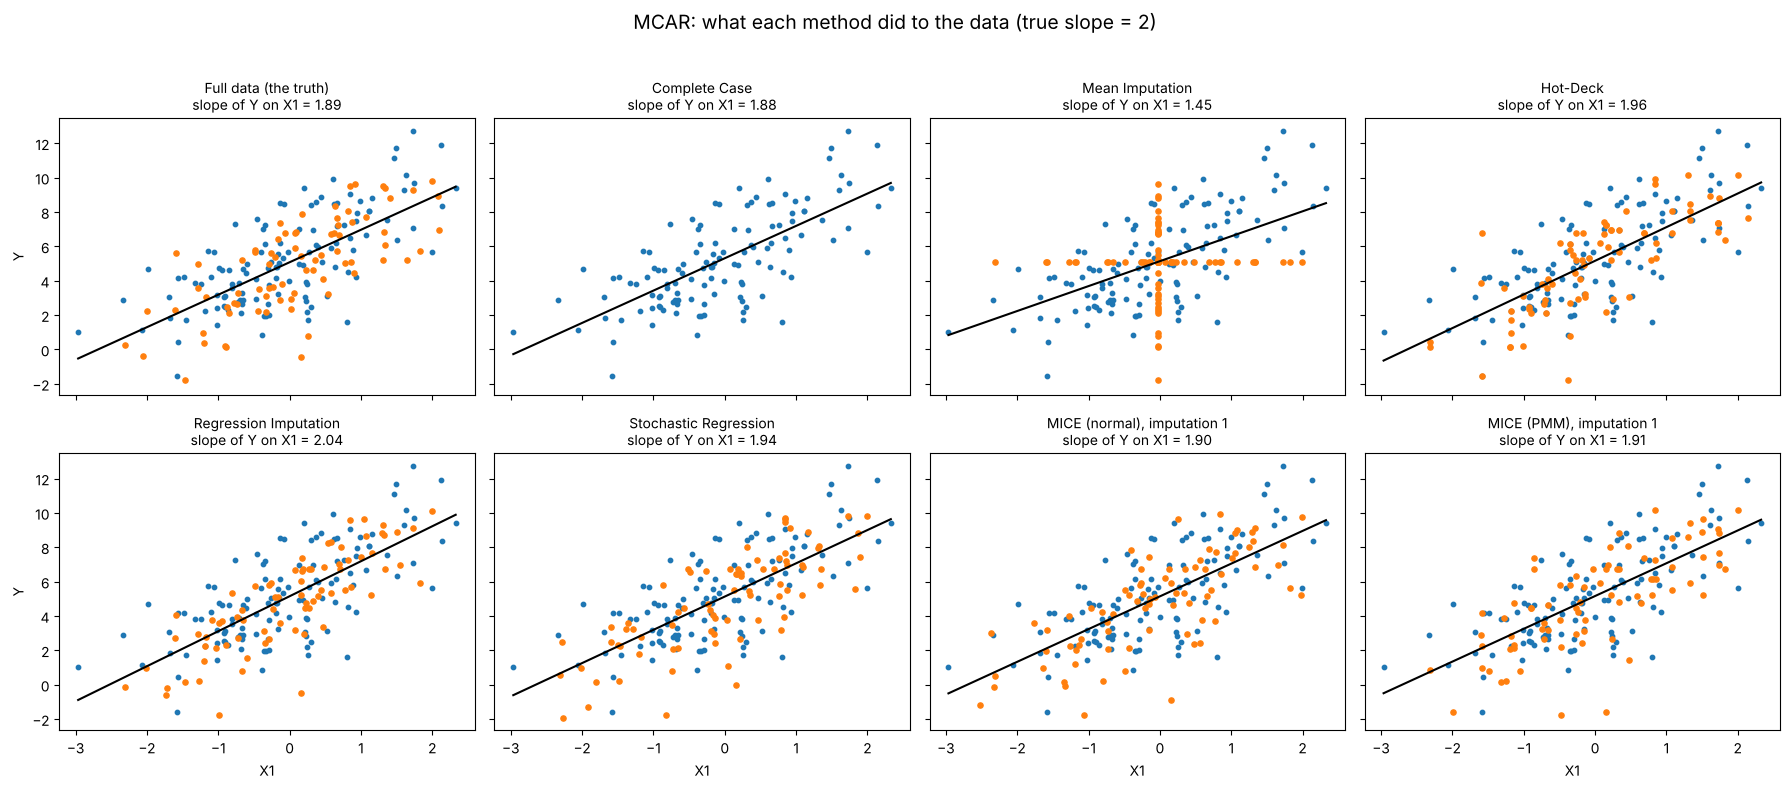

In [66]:
# ===== Step 5.10d — What each method did to the data: MCAR =====
plot_a_scatter("MCAR")

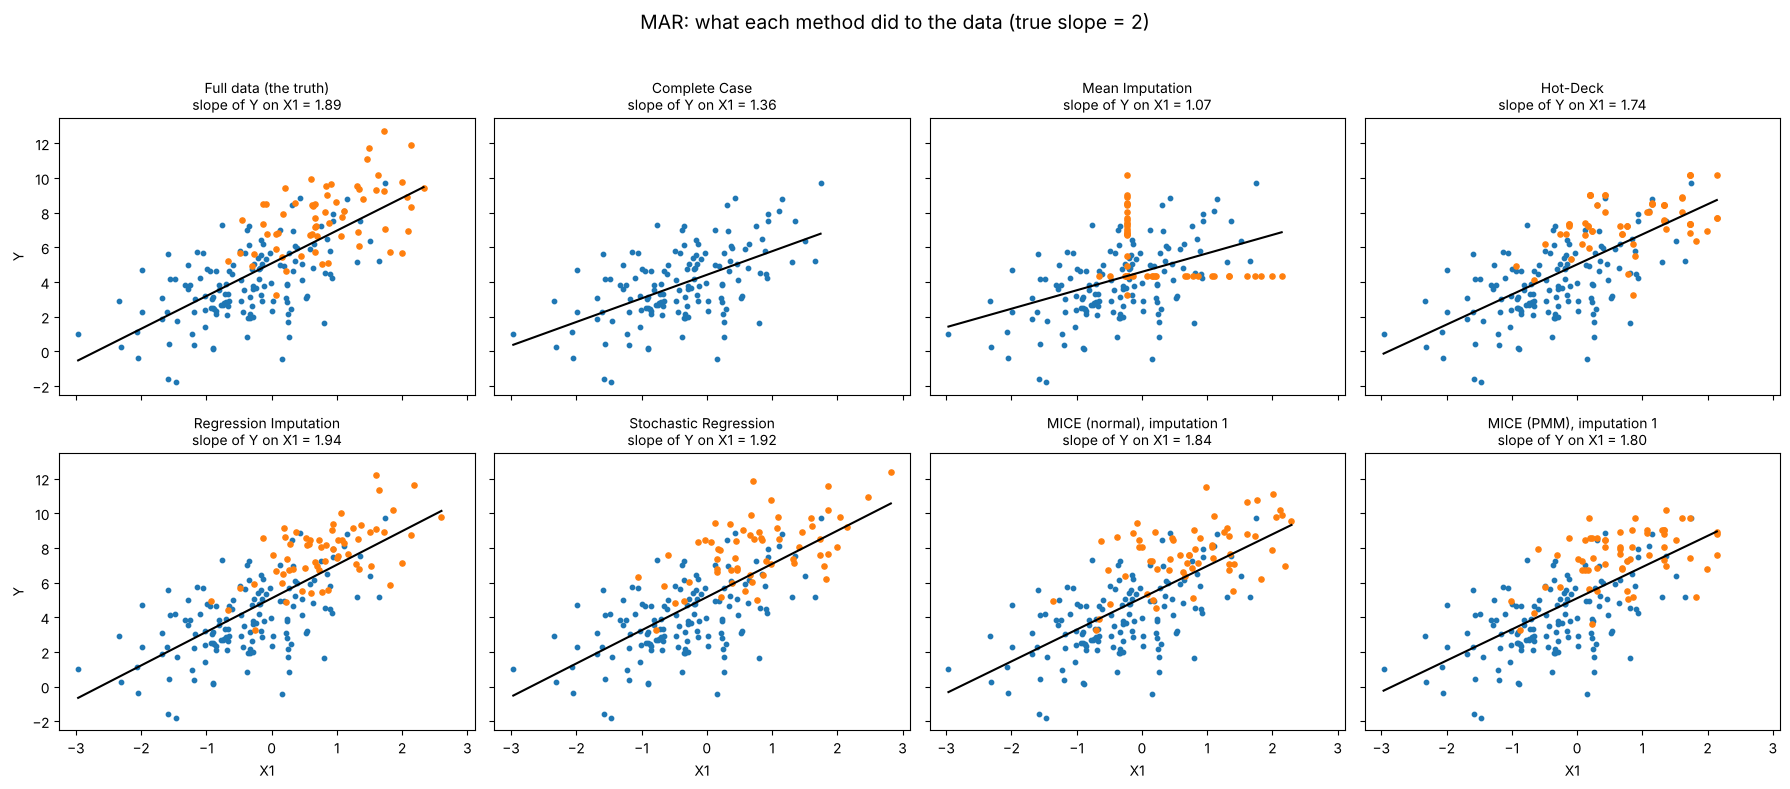

In [67]:
# ===== Step 5.10e — What each method did to the data: MAR =====
plot_a_scatter("MAR")

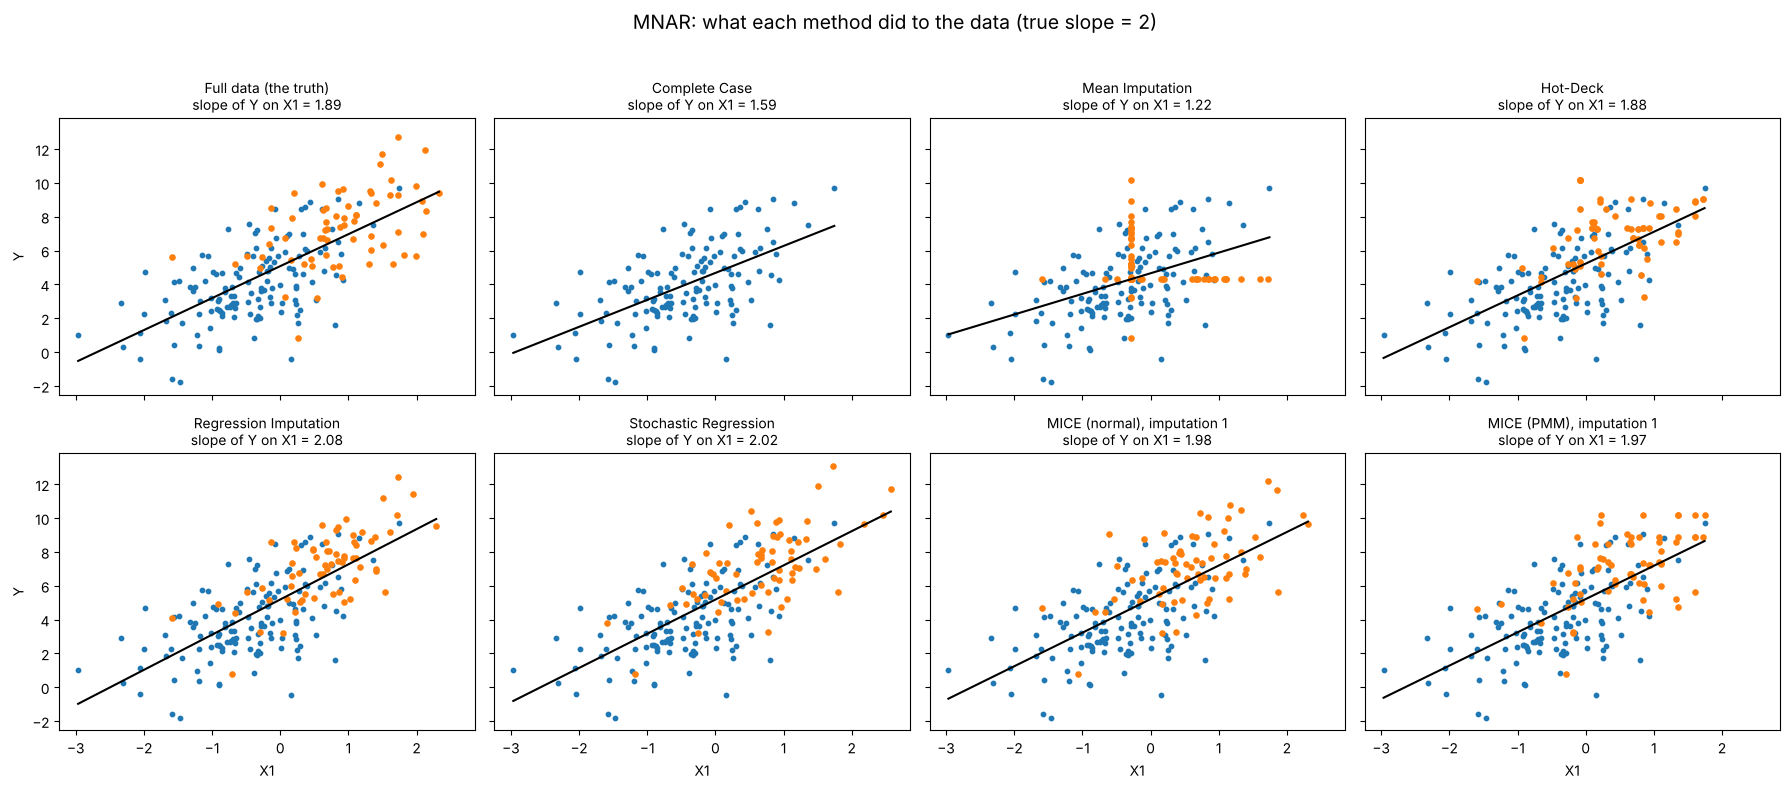

In [68]:
# ===== Step 5.10f — What each method did to the data: MNAR =====
plot_a_scatter("MNAR")

Orange points are rows where a value was missing. Complete case loses those rows; mean imputation puts the filled points on a cross through the average (which flattens the slope); regression imputation puts them exactly on the line (no scatter); the other methods scatter them around the line the way real data look.

# 6. Building confidence intervals (one dataset)

A method gives an estimate of β₁. To say how sure we are, we need a **95% confidence interval**. Four kinds are used in this project:

| Interval | How it is built | Used for |
|---|---|---|
| **Classical** | estimate ± 1.96 × the usual regression formula SE | complete case, mean, hot-deck, regression, stochastic (and the no-missing-data benchmark) |
| **Bootstrap standard** | estimate ± 1.96 × the bootstrap SE | complete case, mean, hot-deck, regression, stochastic, EM |
| **Bootstrap percentile** | the 2.5% and 97.5% points of the bootstrap estimates | the same six methods |
| **Rubin** | pooled estimate ± 1.96 × the Rubin's-rules SE | MICE (normal) and MICE (PMM) |

**The bootstrap.** We do not know the true population, so we treat the sample as if it were the population: draw `n` rows *with replacement*, **redo the whole method** (including filling in the gaps), and record β̂₁. Repeating this `B_BOOT` times gives `B_BOOT` estimates. Their standard deviation is the **bootstrap SE**; their middle 95% is the **percentile interval**.

> There are four common bootstrap confidence intervals: **standard**, **percentile**, **bootstrap-t** and **BCa** (bias-corrected and accelerated). Only the standard and bootstrap-t intervals use the bootstrap SE. We use the **standard** and **percentile** intervals; bootstrap-t (which needs a second bootstrap inside every resample) and BCa are listed as limitations.

For MICE no bootstrap is needed: Rubin's rules already include the extra uncertainty caused by the missing data.

In [69]:
# ===== Step 6a — The bootstrap: resample the rows and redo the WHOLE method =====
def bootstrap_beta1(method, data, rng, B):
    """B bootstrap estimates of beta1. Each resample draws n rows with replacement
    and runs the complete method on it, filling-in of the gaps included."""
    n = len(data)
    estimates_b = np.empty(B)
    for b in range(B):
        resample = data.iloc[rng.integers(0, n, n)].reset_index(drop=True)
        estimates_b[b] = method(resample, rng)[0][1]
    return estimates_b

In [70]:
# ===== Step 6b — From an estimate and its SE (or bootstrap estimates) to an interval =====
def normal_interval(estimate, se):
    """Classical, bootstrap-standard and Rubin intervals all have this form."""
    return estimate - 1.96 * se, estimate + 1.96 * se


def percentile_interval(boot):
    """Bootstrap percentile interval: the 2.5% and 97.5% points of the bootstrap estimates."""
    return np.percentile(boot, 2.5), np.percentile(boot, 97.5)

In [71]:
# ===== Step 6c — All the intervals of every method on the MAR dataset =====
rng = np.random.default_rng(SEED)
BOOTSTRAPPED = ["Complete Case", "Mean Imputation", "Hot-Deck", "Regression Imputation", "Stochastic Regression", "EM"]
METHOD_FUNCS = {"Complete Case": complete_case, "Mean Imputation": mean_imputation, "Hot-Deck": hot_deck,
                "Regression Imputation": regression_imputation, "Stochastic Regression": stochastic_regression,
                "MICE (normal)": mice_normal, "MICE (PMM)": mice_pmm, "EM": em}

def fmt(lo, hi): return f"({lo:.3f}, {hi:.3f})"

rows, demo_boot = [], {}
for name in METHOD_ORDER:
    beta, se = estimates[(name, "MAR")]
    row = {"Method": name, "Estimate": round(beta[1], 3), "Classical": "-", "Bootstrap standard": "-", "Bootstrap percentile": "-", "Rubin": "-"}
    if name.startswith("MICE"):
        row["Rubin"] = fmt(*normal_interval(beta[1], se[1]))
    else:
        if se is not None:
            row["Classical"] = fmt(*normal_interval(beta[1], se[1]))
        boot = bootstrap_beta1(METHOD_FUNCS[name], df_mar, rng, B_BOOT)
        demo_boot[name] = boot
        row["Bootstrap standard"] = fmt(*normal_interval(beta[1], boot.std(ddof=1)))
        row["Bootstrap percentile"] = fmt(*percentile_interval(boot))
    rows.append(row)

print(f"MAR dataset, {B_BOOT} bootstrap resamples per method. True beta1 = 2.")
pd.DataFrame(rows).set_index("Method")

MAR dataset, 200 bootstrap resamples per method. True beta1 = 2.


,Estimate,Classical,Bootstrap standard,Bootstrap percentile,Rubin
Method,,,,,
Complete Case,1.844,"(1.639, 2.050)","(1.643, 2.045)","(1.660, 2.054)",-
Mean Imputation,1.346,"(1.084, 1.607)","(1.054, 1.637)","(1.066, 1.596)",-
Hot-Deck,1.878,"(1.713, 2.042)","(1.613, 2.143)","(1.604, 2.101)",-
Regression Imputation,2.110,"(1.977, 2.244)","(1.927, 2.294)","(1.942, 2.257)",-
Stochastic Regression,2.085,"(1.930, 2.240)","(1.913, 2.257)","(1.862, 2.211)",-
MICE (normal),2.036,-,-,-,"(1.843, 2.228)"
MICE (PMM),1.943,-,-,-,"(1.749, 2.137)"
EM,2.022,-,"(1.856, 2.188)","(1.856, 2.195)",-


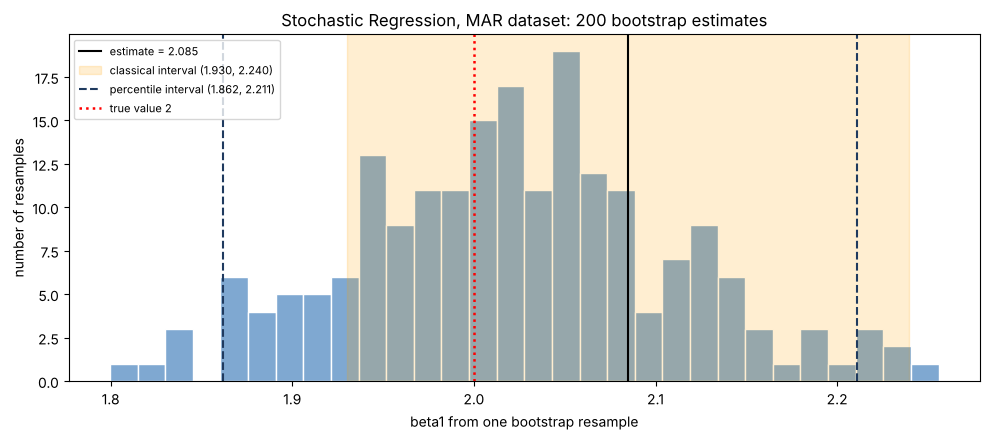

Classical SE = 0.079   bootstrap SE = 0.088
The classical SE treats the filled-in values as real data; the bootstrap repeats the filling-in every time.


In [72]:
# ===== Step 6d — Picture of one bootstrap: stochastic regression on the MAR dataset =====
name = "Stochastic Regression"
boot = demo_boot[name]
beta, se = estimates[(name, "MAR")]
c_lo, c_hi = normal_interval(beta[1], se[1])
p_lo, p_hi = percentile_interval(boot)

plt.figure(figsize=(10, 4.5))
plt.hist(boot, bins=30, color="#7fa8d1", edgecolor="white")
plt.axvline(beta[1], color="black", lw=1.5, label=f"estimate = {beta[1]:.3f}")
plt.axvspan(c_lo, c_hi, color="orange", alpha=0.18, label=f"classical interval {fmt(c_lo, c_hi)}")
plt.axvline(p_lo, color="#1f3a5f", ls="--", lw=1.5, label=f"percentile interval {fmt(p_lo, p_hi)}")
plt.axvline(p_hi, color="#1f3a5f", ls="--", lw=1.5)
plt.axvline(2, color="red", ls=":", lw=1.8, label="true value 2")
plt.xlabel("beta1 from one bootstrap resample"); plt.ylabel("number of resamples")
plt.title(f"{name}, MAR dataset: {B_BOOT} bootstrap estimates")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"Classical SE = {se[1]:.3f}   bootstrap SE = {boot.std(ddof=1):.3f}")
print("The classical SE treats the filled-in values as real data; the bootstrap repeats the filling-in every time.")

**Why one interval is not enough.** The table above gives *one* interval per method. Each one either contains 2 or not — but that is luck: a perfectly good 95% interval still misses 5% of the time, and a bad one can happen to catch the truth. A single bootstrap interval tells us nothing more.

To know whether a *type* of interval can be trusted we must ask: **if we repeated the whole study on many new datasets, how often would the interval contain the truth?** That share is the **coverage probability**, and it can only be estimated with **Monte Carlo**: generate many new datasets from the true model, build the interval on each, and count. That is Section 7.

# 7. The Monte Carlo study

For each of `N_REPS` repetitions:

1. generate a **new** complete dataset from the true model (the population),
2. for each mechanism, delete values with the **same** deletion function,
3. apply all eight methods and build every interval each method has:
   * classical interval from the formula SE,
   * **`B_BOOT` bootstrap resamples** of the incomplete dataset → bootstrap-standard and percentile intervals,
   * Rubin interval for MICE,
4. also analyse the complete data (nothing missing) as a **benchmark**, with a classical and a bootstrap interval.

Then, for every method and every interval type, **coverage = share of the `N_REPS` intervals that contain 2**. A trustworthy 95% interval should cover about 95%.

The bootstrap therefore runs `N_REPS × B_BOOT` times for every method and mechanism (**N × B replication**): with the default settings that is about one million imputations and regressions. The repetitions are independent, so they are spread over several CPU cores, and the results are saved so the long loop only has to run once.

In [73]:
# ===== Step 7a — The methods, and which intervals each one gets =====
METHODS = METHOD_FUNCS
INTERVAL_TYPES = ["Classical", "Bootstrap standard", "Bootstrap percentile", "Rubin"]

availability = pd.DataFrame(
    {"Classical": ["yes (naive)" if m in ("Mean Imputation", "Hot-Deck", "Regression Imputation", "Stochastic Regression")
                   else "yes" if m == "Complete Case" else "-" for m in METHOD_ORDER],
     "Bootstrap standard": ["yes" if m in BOOTSTRAPPED else "-" for m in METHOD_ORDER],
     "Bootstrap percentile": ["yes" if m in BOOTSTRAPPED else "-" for m in METHOD_ORDER],
     "Rubin": ["yes" if m.startswith("MICE") else "-" for m in METHOD_ORDER]},
    index=METHOD_ORDER)
availability

,Classical,Bootstrap standard,Bootstrap percentile,Rubin
Complete Case,yes,yes,yes,-
Mean Imputation,yes (naive),yes,yes,-
Hot-Deck,yes (naive),yes,yes,-
Regression Imputation,yes (naive),yes,yes,-
Stochastic Regression,yes (naive),yes,yes,-
MICE (normal),-,-,-,yes
MICE (PMM),-,-,-,yes
EM,-,yes,yes,-


In [74]:
# ===== Step 7b — One Monte Carlo repetition =====
def one_replication(seed, B=B_BOOT):
    """One new dataset from the true model, damaged under each mechanism, analysed by every method.
    Returns one record per (mechanism, method) with the estimate and everything needed for the intervals."""
    rng = np.random.default_rng(seed)
    full_r = make_data(rng)
    beta_f, se_f = ols(full_r)
    boot_f = bootstrap_beta1(complete_case, full_r, rng, B)          # benchmark: bootstrap with nothing missing

    records = []
    for mech in MECHANISMS:
        data = make_missing(full_r, mech, rng)
        records.append({"Mechanism": mech, "Method": "Full data", "Beta1": beta_f[1], "Beta1_full": beta_f[1],
                        "SE_classical": se_f[1], "SE_rubin": np.nan, "SE_boot": boot_f.std(ddof=1),
                        "Pct_low": np.percentile(boot_f, 2.5), "Pct_high": np.percentile(boot_f, 97.5)})
        for name, method in METHODS.items():
            beta, se = method(data, rng)
            rec = {"Mechanism": mech, "Method": name, "Beta1": beta[1], "Beta1_full": beta_f[1],
                   "SE_classical": np.nan, "SE_rubin": np.nan, "SE_boot": np.nan, "Pct_low": np.nan, "Pct_high": np.nan}
            if name.startswith("MICE"):
                rec["SE_rubin"] = se[1]                                   # Rubin's rules
            elif se is not None:
                rec["SE_classical"] = se[1]                               # formula SE
            if name in BOOTSTRAPPED:
                boot = bootstrap_beta1(method, data, rng, B)              # B resamples of THIS incomplete dataset
                rec["SE_boot"] = boot.std(ddof=1)
                rec["Pct_low"], rec["Pct_high"] = percentile_interval(boot)
            records.append(rec)
    return records

In [75]:
# ===== Step 7c — Run ONE repetition, to see what is recorded =====
seeds = np.random.SeedSequence(MC_SEED).spawn(N_REPS)                 # one independent seed per repetition
demo = pd.DataFrame(one_replication(seeds[0]))
demo[demo["Mechanism"] == "MAR"].round(3)

,Mechanism,Method,Beta1,Beta1_full,SE_classical,SE_rubin,SE_boot,Pct_low,Pct_high
9,MAR,Full data,1.988,1.988,0.075,NaN,0.071,1.850,2.134
10,MAR,Complete Case,1.932,1.988,0.092,NaN,0.086,1.758,2.096
11,MAR,Mean Imputation,1.636,1.988,0.125,NaN,0.120,1.386,1.841
12,MAR,Hot-Deck,1.861,1.988,0.088,NaN,0.100,1.654,2.052
13,MAR,Regression Imputation,2.054,1.988,0.071,NaN,0.088,1.879,2.237
14,MAR,Stochastic Regression,1.989,1.988,0.077,NaN,0.085,1.822,2.155
15,MAR,MICE (normal),1.994,1.988,NaN,0.089,NaN,NaN,NaN
16,MAR,MICE (PMM),1.873,1.988,NaN,0.096,NaN,NaN,NaN
17,MAR,EM,1.985,1.988,NaN,NaN,0.088,1.823,2.149


In [76]:
# ===== Step 7d — Run all N_REPS repetitions (in parallel), or load saved results =====
import time, json
from joblib import Parallel, delayed

settings = {"N": N, "N_REPS": N_REPS, "B_BOOT": B_BOOT, "M_IMPUTATIONS": M_IMPUTATIONS, "MC_SEED": MC_SEED}
results_file = RESULTS_DIR / "monte_carlo_results.csv"
settings_file = RESULTS_DIR / "monte_carlo_settings.json"
partial_file = RESULTS_DIR / "monte_carlo_partial.csv"          # progress so far, in case the run is interrupted
same_settings = settings_file.exists() and json.loads(settings_file.read_text()) == settings

if USE_SAVED_RESULTS and results_file.exists() and same_settings:
    mc = pd.read_csv(results_file)
    print(f"Loaded saved results ({len(mc)} rows) from {results_file} - same settings, so no need to re-run.")
else:
    if partial_file.exists() and same_settings:                   # resume an interrupted run
        done = pd.read_csv(partial_file)
        print(f"Resuming: {done['Rep'].nunique()} of {N_REPS} repetitions were already done.")
    else:
        done = pd.DataFrame()
        partial_file.unlink(missing_ok=True)
        settings_file.write_text(json.dumps(settings))
    todo = [r for r in range(N_REPS) if done.empty or r not in set(done["Rep"])]
    start, chunk = time.time(), 10
    for first in range(0, len(todo), chunk):
        batch = todo[first:first + chunk]
        if N_JOBS == 1:
            out = [one_replication(seeds[r]) for r in batch]
        else:
            out = Parallel(n_jobs=N_JOBS)(delayed(one_replication)(seeds[r]) for r in batch)
        new = pd.DataFrame([dict(rec, Rep=r) for r, recs in zip(batch, out) for rec in recs])
        new.to_csv(partial_file, mode="a", header=not partial_file.exists(), index=False)     # save progress
        print(f"{N_REPS - len(todo) + first + len(batch)} / {N_REPS} repetitions done  ({(time.time() - start) / 60:.1f} min)")
    mc = pd.read_csv(partial_file).sort_values(["Rep"], kind="stable").reset_index(drop=True)
    mc.to_csv(results_file, index=False)
    partial_file.unlink()
    print(f"Saved to {results_file}")

print("Rows:", len(mc), " (= repetitions x 3 mechanisms x 9 analyses, including the no-missing-data benchmark)")

10 / 300 repetitions done  (0.7 min)


20 / 300 repetitions done  (1.4 min)


30 / 300 repetitions done  (2.1 min)


40 / 300 repetitions done  (2.8 min)


50 / 300 repetitions done  (3.5 min)


60 / 300 repetitions done  (4.2 min)


... (20 outputs left out)

270 / 300 repetitions done  (18.9 min)


280 / 300 repetitions done  (19.6 min)


290 / 300 repetitions done  (20.3 min)


300 / 300 repetitions done  (21.0 min)
Saved to results/monte_carlo_results.csv
Rows: 8100  (= repetitions x 3 mechanisms x 9 analyses, including the no-missing-data benchmark)


In [77]:
# ===== Step 7e — Every interval of every repetition, and whether it contains the truth =====
def build_intervals(mc):
    parts = []
    for kind in INTERVAL_TYPES:
        d = mc[["Mechanism", "Method", "Rep", "Beta1"]].copy()
        if kind == "Classical":
            d["Low"], d["High"] = normal_interval(mc["Beta1"], mc["SE_classical"])
        elif kind == "Bootstrap standard":
            d["Low"], d["High"] = normal_interval(mc["Beta1"], mc["SE_boot"])
        elif kind == "Bootstrap percentile":
            d["Low"], d["High"] = mc["Pct_low"], mc["Pct_high"]
        else:
            d["Low"], d["High"] = normal_interval(mc["Beta1"], mc["SE_rubin"])
        d["Interval"] = kind
        parts.append(d.dropna(subset=["Low"]))
    iv = pd.concat(parts, ignore_index=True)
    iv["Covered"] = (iv["Low"] <= 2) & (2 <= iv["High"])
    iv["Width"] = iv["High"] - iv["Low"]
    return iv

iv = build_intervals(mc)
print("Intervals built:", len(iv))
iv.head(8).round(3)

Intervals built: 19800


,Mechanism,Method,Rep,Beta1,Low,High,Interval,Covered,Width
0,MCAR,Full data,0,1.988,1.841,2.134,Classical,True,0.293
1,MCAR,Complete Case,0,1.981,1.804,2.158,Classical,True,0.354
2,MCAR,Mean Imputation,0,1.833,1.592,2.074,Classical,True,0.482
3,MCAR,Hot-Deck,0,1.980,1.810,2.150,Classical,True,0.340
4,MCAR,Regression Imputation,0,2.085,1.956,2.214,Classical,True,0.258
5,MCAR,Stochastic Regression,0,2.027,1.883,2.170,Classical,True,0.287
6,MAR,Full data,0,1.988,1.841,2.134,Classical,True,0.293
7,MAR,Complete Case,0,1.932,1.752,2.111,Classical,True,0.359


In [78]:
# ===== Step 7f — Summary of the estimates: bias, spread and accuracy =====
mc["Error"] = mc["Beta1"] - 2
point = mc.groupby(["Mechanism", "Method"], sort=False).agg(
    Bias=("Error", "mean"), SD=("Beta1", "std"), RMSE=("Error", lambda e: np.sqrt((e ** 2).mean())))
point["Bias vs full"] = (mc["Beta1"] - mc["Beta1_full"]).groupby([mc["Mechanism"], mc["Method"]], sort=False).mean()
point = point[["Bias", "Bias vs full", "SD", "RMSE"]]
point.round(3).head(9)

Bias  Bias vs full     SD   RMSE
Mechanism Method                                                  
MCAR      Full data             -0.000         0.000  0.071  0.071
          Complete Case         -0.005        -0.005  0.091  0.091
          Mean Imputation       -0.396        -0.396  0.141  0.421
          Hot-Deck              -0.096        -0.096  0.108  0.144
          Regression Imputation  0.081         0.081  0.084  0.117
          Stochastic Regression -0.002        -0.002  0.095  0.095
          MICE (normal)         -0.006        -0.005  0.087  0.087
          MICE (PMM)            -0.011        -0.011  0.087  0.087
          EM                    -0.003        -0.002  0.084  0.084

In [79]:
# ===== Step 7g — Summary of the intervals: coverage, width and honesty of the SE =====
coverage = 100 * iv.groupby(["Mechanism", "Method", "Interval"], sort=False)["Covered"].mean().unstack("Interval")[INTERVAL_TYPES]
width = iv.groupby(["Mechanism", "Method", "Interval"], sort=False)["Width"].mean().unstack("Interval")[INTERVAL_TYPES]

honesty = pd.DataFrame({
    "Classical SE / SD": mc.groupby(["Mechanism", "Method"], sort=False)["SE_classical"].mean(),
    "Bootstrap SE / SD": mc.groupby(["Mechanism", "Method"], sort=False)["SE_boot"].mean(),
    "Rubin SE / SD": mc.groupby(["Mechanism", "Method"], sort=False)["SE_rubin"].mean(),
}).div(point["SD"], axis=0)

MC_ERROR = 100 * 1.96 * np.sqrt(0.95 * 0.05 / N_REPS)               # random error of a coverage near 95%
print(f"With {N_REPS} repetitions, a coverage near 95% is accurate to about +/- {MC_ERROR:.1f} points.")
coverage.round(1).head(9)

With 300 repetitions, a coverage near 95% is accurate to about +/- 2.5 points.


Interval                         Classical  Bootstrap standard  \
Mechanism Method                                                 
MCAR      Full data                   94.3                93.7   
          Complete Case               95.0                93.7   
          Mean Imputation             14.7                17.3   
          Hot-Deck                    73.0                85.0   
          Regression Imputation       68.7                83.0   
          Stochastic Regression       85.0                92.0   
          EM                           NaN                93.3   
          MICE (normal)                NaN                 NaN   
          MICE (PMM)                   NaN                 NaN   

Interval                         Bootstrap percentile  Rubin  
Mechanism Method                                              
MCAR      Full data                              93.7    NaN  
          Complete Case                          92.3    NaN  
          Mean Imputation                        13.7    NaN  
          Hot-Deck                               84.3    NaN  
          Regression Imputation                  78.7    NaN  
          Stochastic Regression                  95.0    NaN  
          EM                                     92.7    NaN  
          MICE (normal)                           NaN   95.3  
          MICE (PMM)                              NaN   94.0

# 8. Results, one mechanism at a time

For each mechanism there are two tables and three figures:

* **Estimates table** — bias, spread (SD), RMSE, ranked by RMSE (best first).
* **Intervals table** — the coverage (%) of every interval each method has, and its average width.
* **Figure 1 — spread of the estimates:** one box per method; the red line is the truth.
* **Figure 2 — coverage by interval type:** for each method, one bar per interval type; the dashed line is 95% and the grey band is the Monte Carlo error around it.
* **Figure 3 — honesty of the standard error:** reported SE ÷ true spread of the estimates (1 = honest, below 1 = over-confident), for the classical, bootstrap and Rubin SEs.

The **Full data** row is the benchmark: the same datasets analysed with nothing missing.

In [80]:
# ===== Step 8a — Tables for one mechanism =====
ROW_ORDER = ["Full data"] + METHOD_ORDER

def estimates_table(mech):
    t = point.loc[mech].loc[ROW_ORDER]
    bench, rest = t.loc[["Full data"]], t.drop("Full data").sort_values("RMSE")
    rest.insert(0, "Rank", range(1, len(rest) + 1))
    bench.insert(0, "Rank", "-")
    return pd.concat([bench, rest]).round(3)

def intervals_table(mech):
    cov = coverage.loc[mech].loc[ROW_ORDER].round(1).add_suffix(" cover %")
    wid = width.loc[mech].loc[ROW_ORDER].round(3).add_suffix(" width")
    return pd.concat([cov, wid], axis=1).fillna("-")

In [81]:
# ===== Step 8b — Figure 1: spread of the estimates =====
FAMILY = {"Full data": "#cfcfcf", "Complete Case": "#8c8c8c", "Mean Imputation": "#e08a1e", "Hot-Deck": "#e08a1e",
          "Regression Imputation": "#e08a1e", "Stochastic Regression": "#e08a1e", "MICE (normal)": "#2a7fb8", "MICE (PMM)": "#2a7fb8", "EM": "#2a7fb8"}

def plot_estimates(mech):
    t = mc[mc["Mechanism"] == mech]
    groups = [t.loc[t["Method"] == m, "Beta1"].to_numpy() for m in ROW_ORDER]
    plt.figure(figsize=(11, 4.8))
    bp = plt.boxplot(groups, patch_artist=True, showfliers=False)
    for patch, m in zip(bp["boxes"], ROW_ORDER):
        patch.set_facecolor(FAMILY[m])
    plt.axhline(2, color="red", ls="--", label="true beta1 = 2")
    plt.xticks(range(1, len(ROW_ORDER) + 1), ROW_ORDER, rotation=30, ha="right")
    plt.ylabel("estimate of beta1")
    plt.title(f"{mech}: the beta1 estimates over {N_REPS} repetitions")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [82]:
# ===== Step 8c — Figure 2: coverage of every interval type =====
IV_COLORS = {"Classical": "#e08a1e", "Bootstrap standard": "#7fa8d1", "Bootstrap percentile": "#1f3a5f", "Rubin": "#2e8b57"}

def plot_coverage(mech):
    t = coverage.loc[mech].loc[ROW_ORDER]
    y = np.arange(len(t)); h = 0.2
    plt.figure(figsize=(11, 6))
    for k, kind in enumerate(INTERVAL_TYPES):
        vals = t[kind]
        ok = vals.notna().to_numpy()
        plt.barh(y[ok] + (k - 1.5) * h, vals[ok], h, color=IV_COLORS[kind], label=kind)
    plt.axvline(95, color="black", ls="--")
    plt.axvspan(95 - MC_ERROR, 95 + MC_ERROR, color="grey", alpha=0.25)
    plt.yticks(y, t.index); plt.gca().invert_yaxis()
    plt.xlim(0, 100); plt.xlabel("coverage of the 95% interval (%)")
    plt.title(f"{mech}: how often each interval contains the true beta1 (target 95%)")
    plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4, fontsize=8, frameon=False)
    plt.tight_layout()
    plt.show()

In [83]:
# ===== Step 8d — Figure 3: honesty of the standard error =====
SE_COLORS = {"Classical SE / SD": "#e08a1e", "Bootstrap SE / SD": "#1f3a5f", "Rubin SE / SD": "#2e8b57"}

def plot_honesty(mech):
    t = honesty.loc[mech].loc[ROW_ORDER]
    y = np.arange(len(t)); h = 0.27
    plt.figure(figsize=(11, 5.5))
    for k, col in enumerate(SE_COLORS):
        vals = t[col]; ok = vals.notna().to_numpy()
        plt.barh(y[ok] + (k - 1) * h, vals[ok], h, color=SE_COLORS[col], label=col.replace(" / SD", ""))
    plt.axvline(1, color="black", ls="--")
    plt.yticks(y, t.index); plt.gca().invert_yaxis()
    plt.xlabel("reported SE / true spread of the estimates   (1 = honest, below 1 = over-confident)")
    plt.title(f"{mech}: does each standard error tell the truth about the uncertainty?")
    plt.legend(loc="lower right", fontsize=8)
    plt.tight_layout()
    plt.show()

## 8.1  MCAR — all methods compared

In [84]:
# ===== Step 8e — MCAR: the estimates =====
estimates_table("MCAR")

,Rank,Bias,Bias vs full,SD,RMSE
Method,,,,,
Full data,-,-0.000,0.000,0.071,0.071
EM,1,-0.003,-0.002,0.084,0.084
MICE (normal),2,-0.006,-0.005,0.087,0.087
MICE (PMM),3,-0.011,-0.011,0.087,0.087
Complete Case,4,-0.005,-0.005,0.091,0.091
Stochastic Regression,5,-0.002,-0.002,0.095,0.095
Regression Imputation,6,0.081,0.081,0.084,0.117
Hot-Deck,7,-0.096,-0.096,0.108,0.144
Mean Imputation,8,-0.396,-0.396,0.141,0.421


In [85]:
# ===== Step 8f — MCAR: coverage and width of every interval =====
intervals_table("MCAR")

Interval,Classical cover %,Bootstrap standard cover %,Bootstrap percentile cover %,Rubin cover %,Classical width,Bootstrap standard width,Bootstrap percentile width,Rubin width
Method,,,,,,,,
Full data,94.3,93.7,93.7,-,0.281,0.281,0.275,-
Complete Case,95.0,93.7,92.3,-,0.352,0.352,0.344,-
Mean Imputation,14.7,17.3,13.7,-,0.492,0.54,0.527,-
Hot-Deck,73.0,85.0,84.3,-,0.332,0.416,0.407,-
Regression Imputation,68.7,83.0,78.7,-,0.245,0.325,0.319,-
Stochastic Regression,85.0,92.0,95.0,-,0.279,0.349,0.342,-
MICE (normal),-,-,-,95.3,-,-,-,0.329
MICE (PMM),-,-,-,94.0,-,-,-,0.327
EM,-,93.3,92.7,-,-,0.323,0.317,-


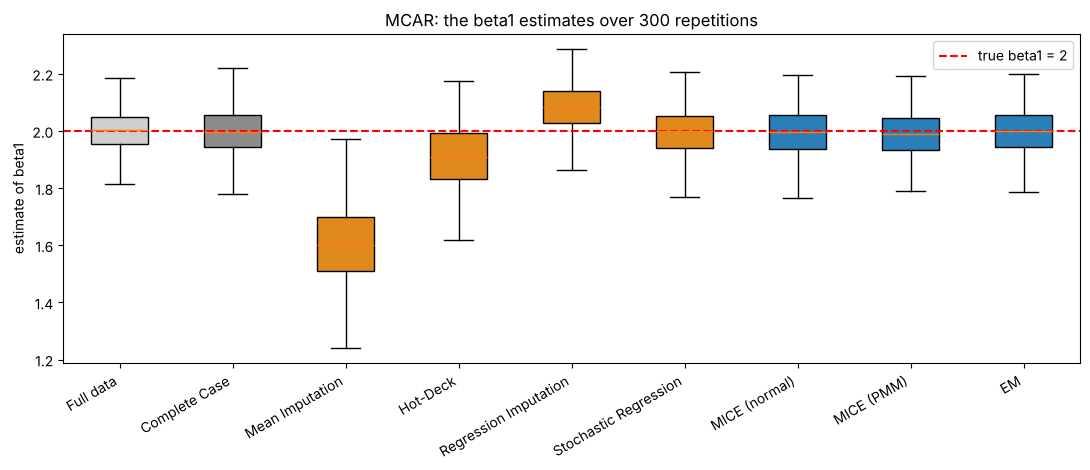

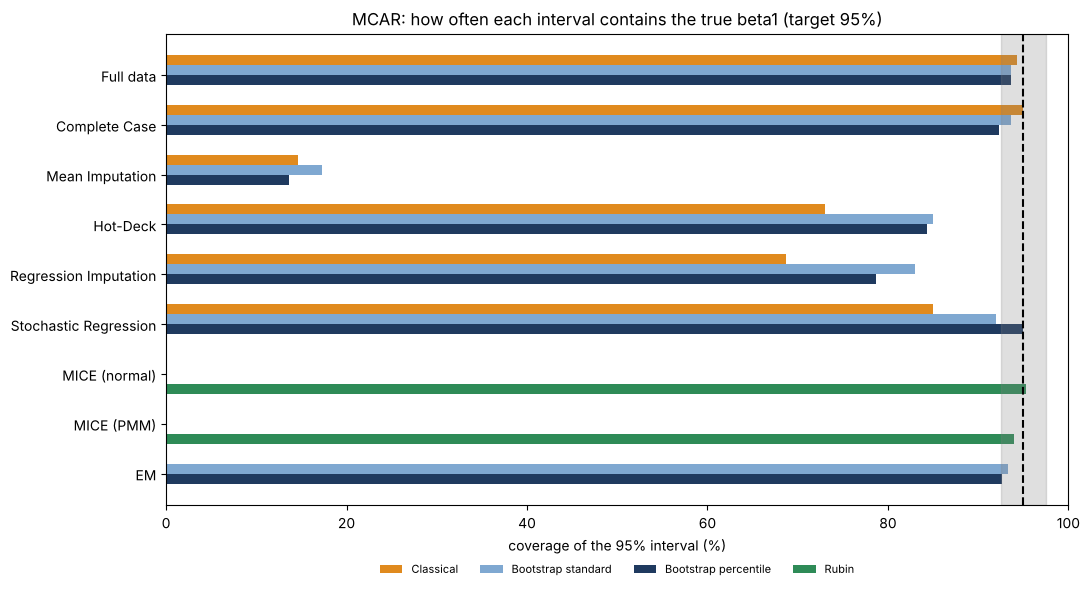

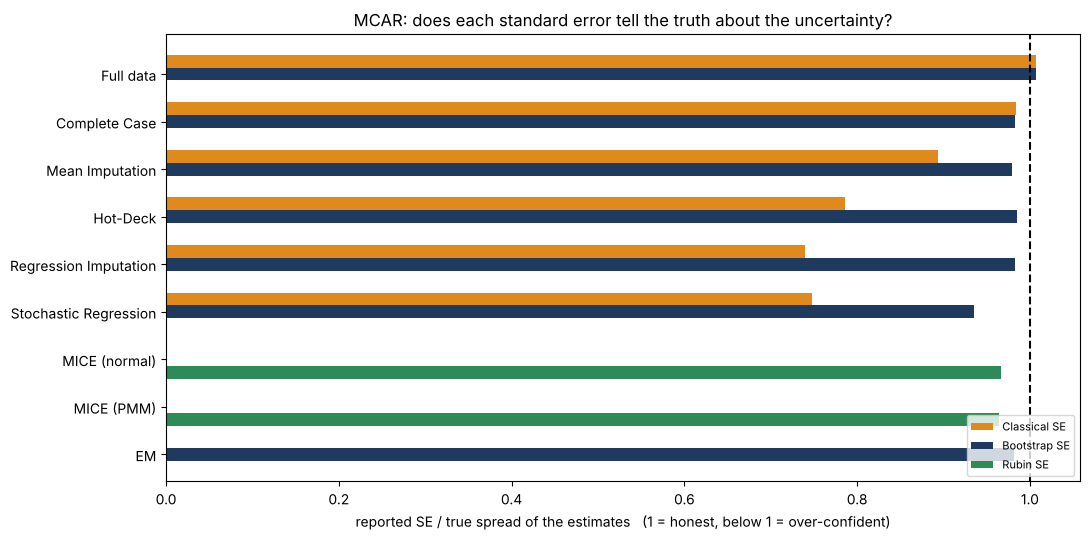

In [86]:
# ===== Step 8g — MCAR: figures =====
plot_estimates("MCAR")
plot_coverage("MCAR")
plot_honesty("MCAR")

## 8.2  MAR — all methods compared

In [87]:
# ===== Step 8h — MAR: the estimates =====
estimates_table("MAR")

,Rank,Bias,Bias vs full,SD,RMSE
Method,,,,,
Full data,-,-0.000,0.000,0.071,0.071
EM,1,0.001,0.001,0.090,0.090
MICE (normal),2,-0.003,-0.003,0.090,0.090
Stochastic Regression,3,0.003,0.003,0.098,0.098
MICE (PMM),4,-0.050,-0.050,0.100,0.112
Regression Imputation,5,0.082,0.083,0.091,0.123
Complete Case,6,-0.103,-0.103,0.100,0.144
Hot-Deck,7,-0.151,-0.151,0.124,0.196
Mean Imputation,8,-0.485,-0.485,0.140,0.505


In [88]:
# ===== Step 8i — MAR: coverage and width of every interval =====
intervals_table("MAR")

Interval,Classical cover %,Bootstrap standard cover %,Bootstrap percentile cover %,Rubin cover %,Classical width,Bootstrap standard width,Bootstrap percentile width,Rubin width
Method,,,,,,,,
Full data,94.3,93.7,93.7,-,0.281,0.281,0.275,-
Complete Case,77.0,75.0,73.3,-,0.362,0.362,0.355,-
Mean Imputation,4.7,4.3,3.7,-,0.502,0.512,0.5,-
Hot-Deck,57.3,73.7,72.3,-,0.345,0.467,0.459,-
Regression Imputation,66.7,84.7,81.3,-,0.254,0.346,0.34,-
Stochastic Regression,82.3,94.7,94.7,-,0.28,0.366,0.359,-
MICE (normal),-,-,-,94.0,-,-,-,0.343
MICE (PMM),-,-,-,87.0,-,-,-,0.355
EM,-,93.0,92.7,-,-,0.338,0.332,-


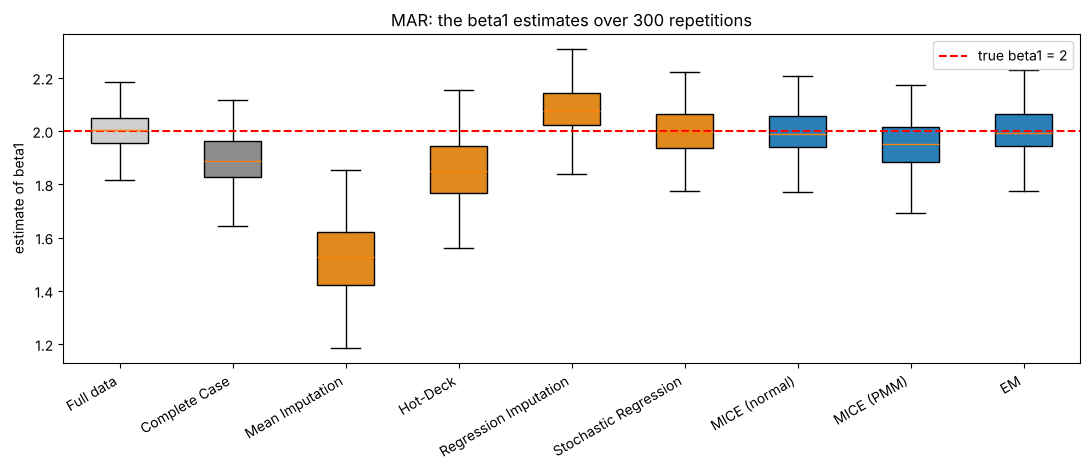

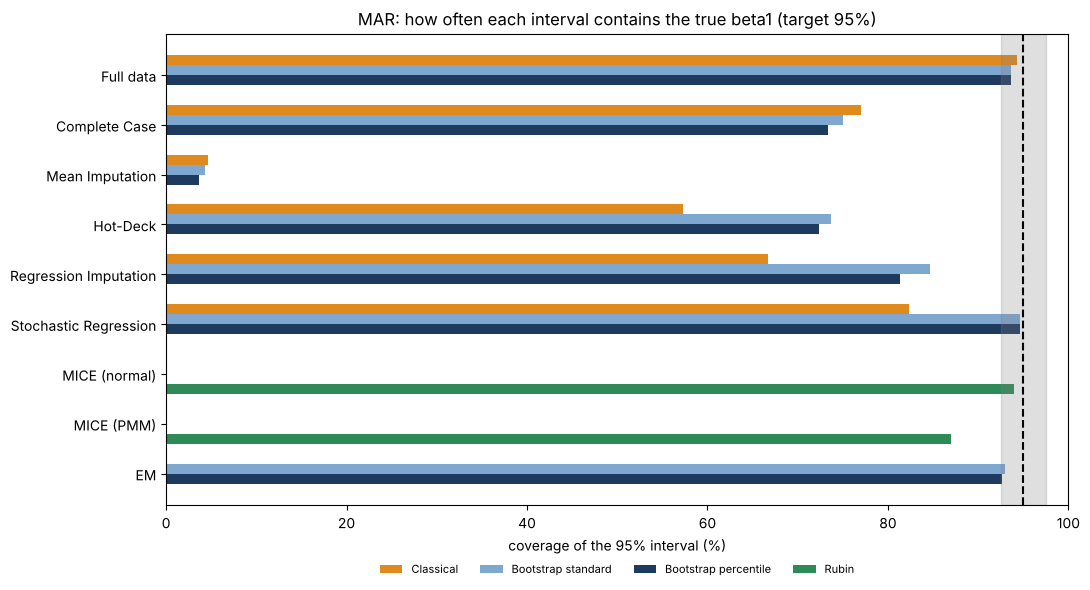

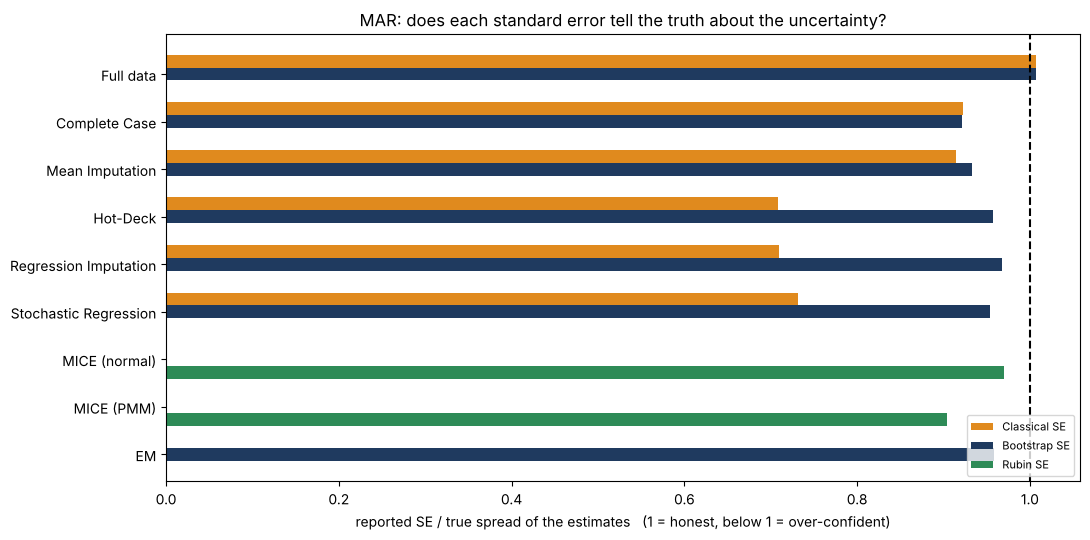

In [89]:
# ===== Step 8j — MAR: figures =====
plot_estimates("MAR")
plot_coverage("MAR")
plot_honesty("MAR")

## 8.3  MNAR — all methods compared

In [90]:
# ===== Step 8k — MNAR: the estimates =====
estimates_table("MNAR")

,Rank,Bias,Bias vs full,SD,RMSE
Method,,,,,
Full data,-,-0.000,0.000,0.071,0.071
MICE (PMM),1,0.019,0.019,0.117,0.119
MICE (normal),2,0.068,0.069,0.099,0.120
EM,3,0.071,0.071,0.099,0.122
Complete Case,4,-0.060,-0.060,0.108,0.124
Stochastic Regression,5,0.074,0.074,0.107,0.129
Hot-Deck,6,-0.047,-0.047,0.127,0.135
Regression Imputation,7,0.157,0.158,0.103,0.188
Mean Imputation,8,-0.573,-0.573,0.158,0.594


In [91]:
# ===== Step 8l — MNAR: coverage and width of every interval =====
intervals_table("MNAR")

Interval,Classical cover %,Bootstrap standard cover %,Bootstrap percentile cover %,Rubin cover %,Classical width,Bootstrap standard width,Bootstrap percentile width,Rubin width
Method,,,,,,,,
Full data,94.3,93.7,93.7,-,0.281,0.281,0.275,-
Complete Case,87.0,87.0,86.3,-,0.402,0.401,0.393,-
Mean Imputation,4.3,4.0,4.0,-,0.579,0.586,0.572,-
Hot-Deck,84.7,91.3,90.7,-,0.378,0.479,0.469,-
Regression Imputation,41.7,61.3,57.3,-,0.272,0.374,0.365,-
Stochastic Regression,75.0,87.3,88.3,-,0.304,0.393,0.385,-
MICE (normal),-,-,-,89.0,-,-,-,0.372
MICE (PMM),-,-,-,89.0,-,-,-,0.383
EM,-,87.0,84.3,-,-,0.362,0.354,-


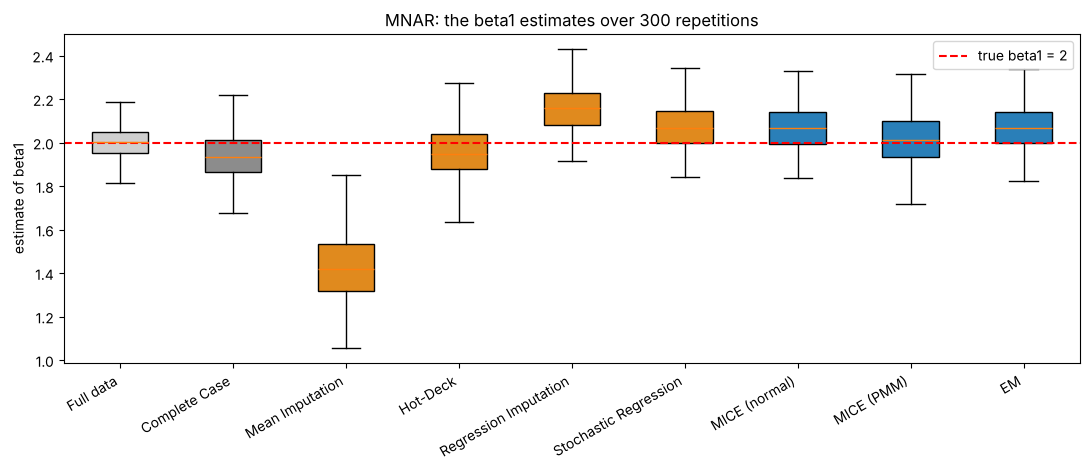

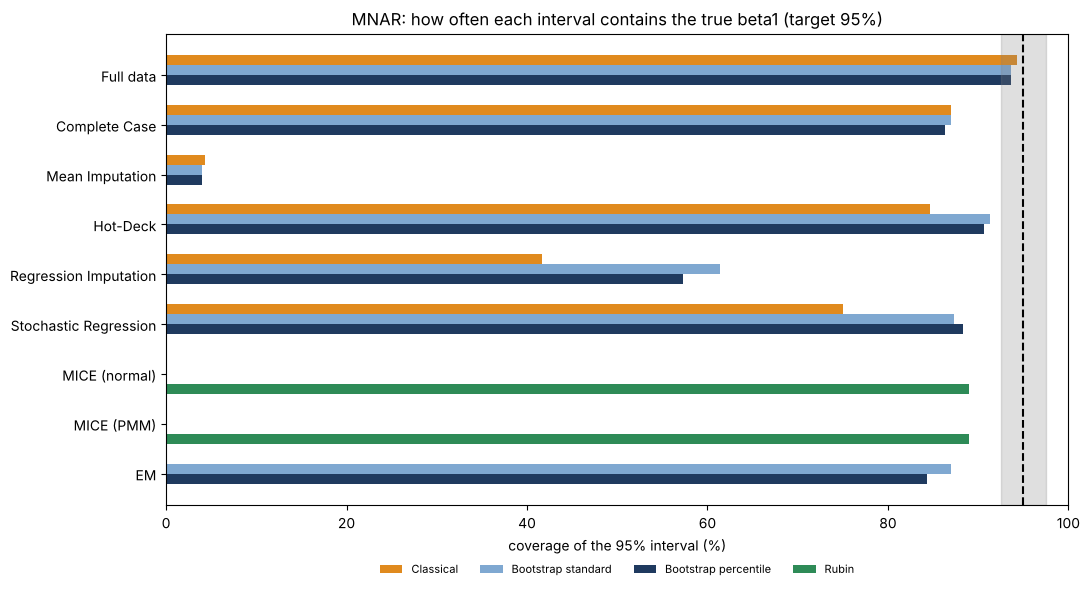

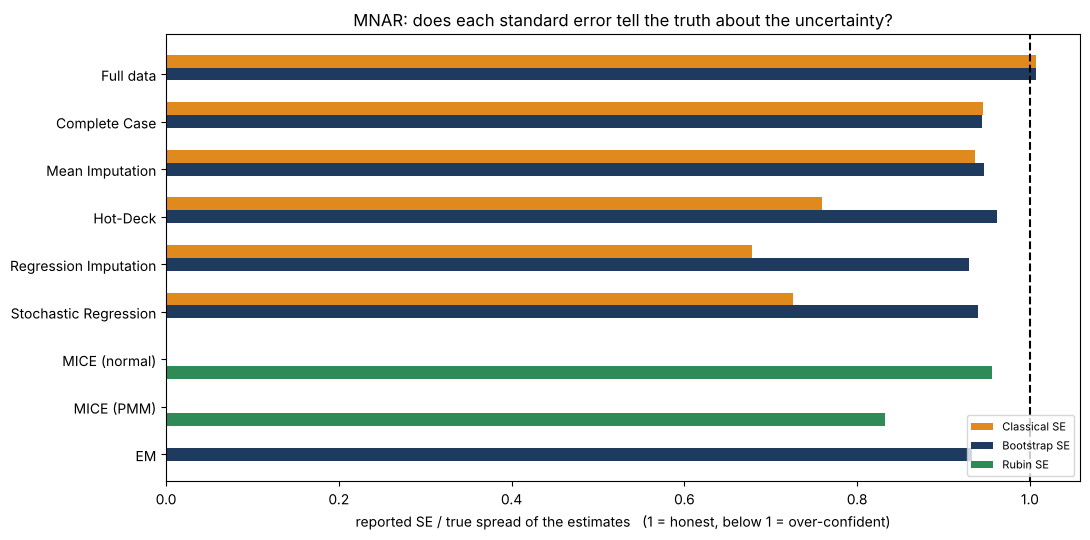

In [92]:
# ===== Step 8m — MNAR: figures =====
plot_estimates("MNAR")
plot_coverage("MNAR")
plot_honesty("MNAR")

## 8.4  Classical versus bootstrap intervals, seen one by one (MAR)

Each horizontal line is the 95% interval from **one** simulated dataset (the first 40 of the `N_REPS`). Green = contains the truth, red = misses. Left: the classical interval; right: the bootstrap percentile interval of the same method on the same datasets.

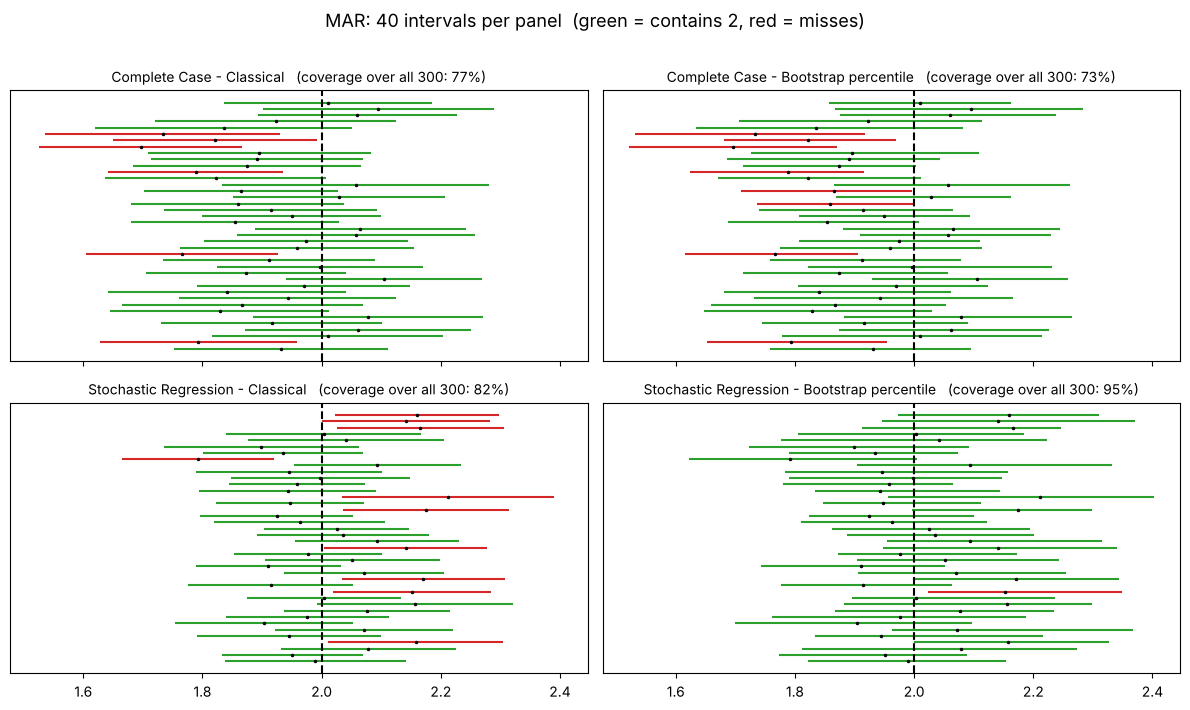

In [93]:
# ===== Step 8n — Individual intervals: classical vs bootstrap percentile (MAR) =====
def plot_individual(mech, methods, n_show=40):
    fig, axes = plt.subplots(len(methods), 2, figsize=(12, 3.6 * len(methods)), sharex=True)
    for row, m in enumerate(methods):
        for col, kind in enumerate(["Classical", "Bootstrap percentile"]):
            ax = axes[row, col]
            t = iv[(iv["Mechanism"] == mech) & (iv["Method"] == m) & (iv["Interval"] == kind) & (iv["Rep"] < n_show)]
            ax.hlines(t["Rep"], t["Low"], t["High"], colors=np.where(t["Covered"], "tab:green", "tab:red"))
            ax.plot(t["Beta1"], t["Rep"], "k.", ms=3)
            ax.axvline(2, color="black", ls="--"); ax.set_yticks([])
            ax.set_title(f"{m} - {kind}   (coverage over all {N_REPS}: {coverage.loc[(mech, m), kind]:.0f}%)", fontsize=10)
    fig.suptitle(f"{mech}: {n_show} intervals per panel  (green = contains 2, red = misses)", fontsize=13)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

plot_individual("MAR", ["Complete Case", "Stochastic Regression"])

## 8.5  Overview — before and after the bootstrap

Each cell is the coverage of one method under one mechanism. **Left:** the interval an analyst gets *without* a bootstrap (classical; Rubin for MICE). **Right:** with the bootstrap percentile interval (Rubin for MICE, which needs no bootstrap). Read down a column to compare methods within a mechanism.

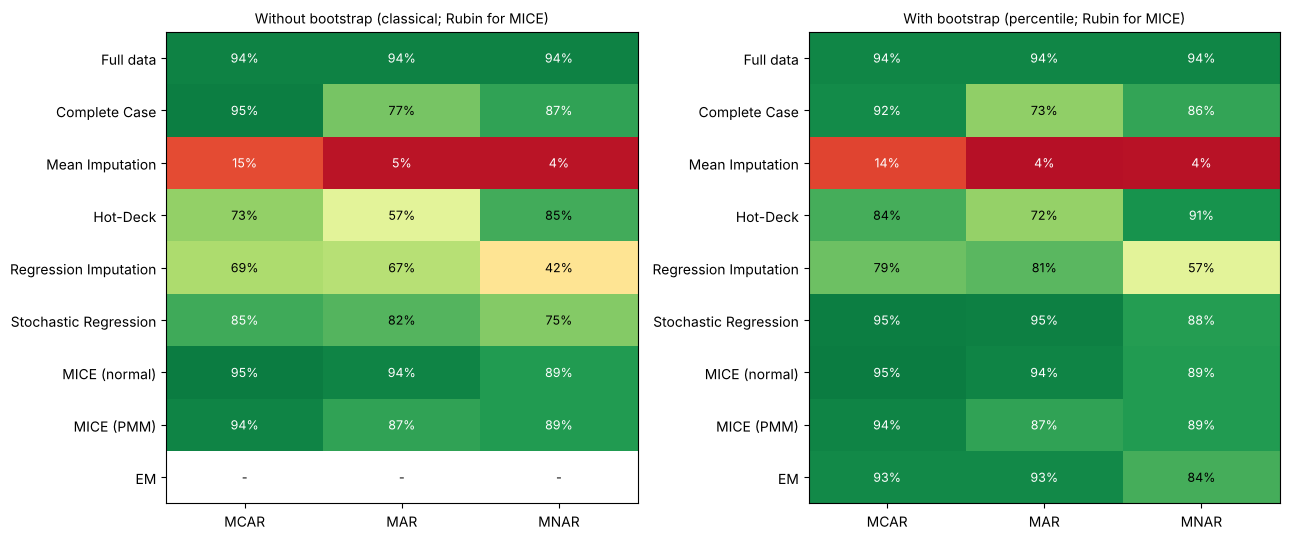

In [94]:
# ===== Step 8o — Coverage heat maps: without and with the bootstrap =====
def coverage_grid(kind):
    g = pd.DataFrame(index=ROW_ORDER, columns=MECHANISMS, dtype=float)
    for mech in MECHANISMS:
        for m in ROW_ORDER:
            use = "Rubin" if m.startswith("MICE") else kind
            g.loc[m, mech] = coverage.loc[(mech, m), use]
    return g

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (kind, title) in zip(axes, [("Classical", "Without bootstrap (classical; Rubin for MICE)"),
                                     ("Bootstrap percentile", "With bootstrap (percentile; Rubin for MICE)")]):
    g = coverage_grid(kind)
    im = ax.imshow(g.to_numpy(dtype=float), cmap="RdYlGn", vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(3)); ax.set_xticklabels(MECHANISMS)
    ax.set_yticks(range(len(g))); ax.set_yticklabels(g.index)
    for i in range(g.shape[0]):
        for j in range(g.shape[1]):
            v = g.iloc[i, j]
            dark = (not np.isnan(v)) and (v >= 85 or v <= 15)
            ax.text(j, i, "-" if np.isnan(v) else f"{v:.0f}%", ha="center", va="center", fontsize=9, color="white" if dark else "black")
    ax.set_title(title, fontsize=10)
plt.tight_layout()
plt.show()

# 9. Master tables and findings

First all results in consolidated tables (also saved as CSV files), then the best method under each mechanism, then text **generated from the results** (so its numbers always match the tables), followed by the interpretation.

In [95]:
# ===== Step 9a — Settings used =====
print(f"N = {N} observations | true beta1 = 2 | {N_REPS} Monte Carlo repetitions | {B_BOOT} bootstrap resamples inside each | "
      f"{M_IMPUTATIONS} imputations (MICE) | Monte Carlo error of a coverage near 95%: +/- {MC_ERROR:.1f} points")

N = 200 observations | true beta1 = 2 | 300 Monte Carlo repetitions | 200 bootstrap resamples inside each | 10 imputations (MICE) | Monte Carlo error of a coverage near 95%: +/- 2.5 points


In [96]:
# ===== Step 9b — Master table: estimates =====
with pd.option_context("display.max_rows", None):
    display(point.round(3))

Bias  Bias vs full     SD   RMSE
Mechanism Method                                                  
MCAR      Full data             -0.000         0.000  0.071  0.071
          Complete Case         -0.005        -0.005  0.091  0.091
          Mean Imputation       -0.396        -0.396  0.141  0.421
          Hot-Deck              -0.096        -0.096  0.108  0.144
          Regression Imputation  0.081         0.081  0.084  0.117
          Stochastic Regression -0.002        -0.002  0.095  0.095
          MICE (normal)         -0.006        -0.005  0.087  0.087
          MICE (PMM)            -0.011        -0.011  0.087  0.087
          EM                    -0.003        -0.002  0.084  0.084
MAR       Full data             -0.000         0.000  0.071  0.071
          Complete Case         -0.103        -0.103  0.100  0.144
          Mean Imputation       -0.485        -0.485  0.140  0.505
          Hot-Deck              -0.151        -0.151  0.124  0.196
          Regression Imputation  0.082         0.083  0.091  0.123
          Stochastic Regression  0.003         0.003  0.098  0.098
          MICE (normal)         -0.003        -0.003  0.090  0.090
          MICE (PMM)            -0.050        -0.050  0.100  0.112
          EM                     0.001         0.001  0.090  0.090
MNAR      Full data             -0.000         0.000  0.071  0.071
          Complete Case         -0.060        -0.060  0.108  0.124
          Mean Imputation       -0.573        -0.573  0.158  0.594
          Hot-Deck              -0.047        -0.047  0.127  0.135
          Regression Imputation  0.157         0.158  0.103  0.188
          Stochastic Regression  0.074         0.074  0.107  0.129
          MICE (normal)          0.068         0.069  0.099  0.120
          MICE (PMM)             0.019         0.019  0.117  0.119
          EM                     0.071         0.071  0.099  0.122

In [97]:
# ===== Step 9c — Master table: coverage (%) of every interval =====
with pd.option_context("display.max_rows", None):
    display(coverage.round(1).fillna("-"))

Interval                        Classical Bootstrap standard  \
Mechanism Method                                               
MCAR      Full data                  94.3               93.7   
          Complete Case              95.0               93.7   
          Mean Imputation            14.7               17.3   
          Hot-Deck                   73.0               85.0   
          Regression Imputation      68.7               83.0   
          Stochastic Regression      85.0               92.0   
          EM                            -               93.3   
          MICE (normal)                 -                  -   
          MICE (PMM)                    -                  -   
MAR       Full data                  94.3               93.7   
          Complete Case              77.0               75.0   
          Mean Imputation             4.7                4.3   
          Hot-Deck                   57.3               73.7   
          Regression Imputation      66.7               84.7   
          Stochastic Regression      82.3               94.7   
          EM                            -               93.0   
          MICE (normal)                 -                  -   
          MICE (PMM)                    -                  -   
MNAR      Full data                  94.3               93.7   
          Complete Case              87.0               87.0   
          Mean Imputation             4.3                4.0   
          Hot-Deck                   84.7               91.3   
          Regression Imputation      41.7               61.3   
          Stochastic Regression      75.0               87.3   
          EM                            -               87.0   
          MICE (normal)                 -                  -   
          MICE (PMM)                    -                  -   

Interval                        Bootstrap percentile Rubin  
Mechanism Method                                            
MCAR      Full data                             93.7     -  
          Complete Case                         92.3     -  
          Mean Imputation                       13.7     -  
          Hot-Deck                              84.3     -  
          Regression Imputation                 78.7     -  
          Stochastic Regression                 95.0     -  
          EM                                    92.7     -  
          MICE (normal)                            -  95.3  
          MICE (PMM)                               -  94.0  
MAR       Full data                             93.7     -  
          Complete Case                         73.3     -  
          Mean Imputation                        3.7     -  
          Hot-Deck                              72.3     -  
          Regression Imputation                 81.3     -  
          Stochastic Regression                 94.7     -  
          EM                                    92.7     -  
          MICE (normal)                            -  94.0  
          MICE (PMM)                               -  87.0  
MNAR      Full data                             93.7     -  
          Complete Case                         86.3     -  
          Mean Imputation                        4.0     -  
          Hot-Deck                              90.7     -  
          Regression Imputation                 57.3     -  
          Stochastic Regression                 88.3     -  
          EM                                    84.3     -  
          MICE (normal)                            -  89.0  
          MICE (PMM)                               -  89.0

In [98]:
# ===== Step 9d — Scoreboard: bias, RMSE and coverage with and without the bootstrap =====
score = pd.DataFrame(index=pd.MultiIndex.from_product([MECHANISMS, ROW_ORDER], names=["Mechanism", "Method"]))
score["Bias"] = point["Bias"]; score["RMSE"] = point["RMSE"]
score["Cover % (classical / Rubin)"] = [coverage.loc[(me, m), "Rubin" if m.startswith("MICE") else "Classical"] for me, m in score.index]
score["Cover % (bootstrap percentile / Rubin)"] = [coverage.loc[(me, m), "Rubin" if m.startswith("MICE") else "Bootstrap percentile"] for me, m in score.index]
with pd.option_context("display.max_rows", None):
    display(score.round(3).fillna("-"))

Bias   RMSE Cover % (classical / Rubin)  \
Mechanism Method                                                            
MCAR      Full data             -0.000  0.071                      94.333   
          Complete Case         -0.005  0.091                        95.0   
          Mean Imputation       -0.396  0.421                      14.667   
          Hot-Deck              -0.096  0.144                        73.0   
          Regression Imputation  0.081  0.117                      68.667   
          Stochastic Regression -0.002  0.095                        85.0   
          MICE (normal)         -0.006  0.087                      95.333   
          MICE (PMM)            -0.011  0.087                        94.0   
          EM                    -0.003  0.084                           -   
MAR       Full data             -0.000  0.071                      94.333   
          Complete Case         -0.103  0.144                        77.0   
          Mean Imputation       -0.485  0.505                       4.667   
          Hot-Deck              -0.151  0.196                      57.333   
          Regression Imputation  0.082  0.123                      66.667   
          Stochastic Regression  0.003  0.098                      82.333   
          MICE (normal)         -0.003  0.090                        94.0   
          MICE (PMM)            -0.050  0.112                        87.0   
          EM                     0.001  0.090                           -   
MNAR      Full data             -0.000  0.071                      94.333   
          Complete Case         -0.060  0.124                        87.0   
          Mean Imputation       -0.573  0.594                       4.333   
          Hot-Deck              -0.047  0.135                      84.667   
          Regression Imputation  0.157  0.188                      41.667   
          Stochastic Regression  0.074  0.129                        75.0   
          MICE (normal)          0.068  0.120                        89.0   
          MICE (PMM)             0.019  0.119                        89.0   
          EM                     0.071  0.122                           -   

                                 Cover % (bootstrap percentile / Rubin)  
Mechanism Method                                                         
MCAR      Full data                                              93.667  
          Complete Case                                          92.333  
          Mean Imputation                                        13.667  
          Hot-Deck                                               84.333  
          Regression Imputation                                  78.667  
          Stochastic Regression                                  95.000  
          MICE (normal)                                          95.333  
          MICE (PMM)                                             94.000  
          EM                                                     92.667  
MAR       Full data                                              93.667  
          Complete Case                                          73.333  
          Mean Imputation                                         3.667  
          Hot-Deck                                               72.333  
          Regression Imputation                                  81.333  
          Stochastic Regression                                  94.667  
          MICE (normal)                                          94.000  
          MICE (PMM)                                             87.000  
          EM                                                     92.667  
MNAR      Full data                                              93.667  
          Complete Case                                          86.333  
          Mean Imputation                                         4.000  
          Hot-Deck                                               90.667  
          Regression Imp

In [99]:
# ===== Step 9e — Which method is best under each mechanism? =====
def best_cover(mech, m):
    """Coverage of the method's best-suited interval: Rubin for MICE, bootstrap percentile otherwise."""
    return coverage.loc[(mech, m), "Rubin" if m.startswith("MICE") else "Bootstrap percentile"]

winners = []
for mech in MECHANISMS:
    t = point.loc[mech].drop("Full data")
    bc = pd.Series({m: best_cover(mech, m) for m in METHOD_ORDER})
    honest = bc[bc >= 90].index
    winners.append({"Mechanism": mech, "Lowest RMSE": t["RMSE"].idxmin(), "Smallest |bias|": t["Bias"].abs().idxmin(),
                    "Coverage closest to 95%": (bc - 95).abs().idxmin(),
                    "Lowest RMSE among methods with coverage >= 90%": t.loc[honest, "RMSE"].idxmin() if len(honest) else "none"})
pd.DataFrame(winners).set_index("Mechanism")

,Lowest RMSE,Smallest |bias|,Coverage closest to 95%,Lowest RMSE among methods with coverage >= 90%
Mechanism,,,,
MCAR,EM,Stochastic Regression,Stochastic Regression,EM
MAR,EM,EM,Stochastic Regression,EM
MNAR,MICE (PMM),MICE (PMM),Hot-Deck,Hot-Deck


In [100]:
# ===== Step 9f — Save the summary tables =====
point.round(5).to_csv(RESULTS_DIR / "summary_estimates.csv")
coverage.round(2).to_csv(RESULTS_DIR / "summary_coverage.csv")
width.round(5).to_csv(RESULTS_DIR / "summary_interval_width.csv")
honesty.round(4).to_csv(RESULTS_DIR / "summary_se_honesty.csv")
walk.round(5).to_csv(RESULTS_DIR / "walkthrough_estimates.csv")
print("Saved in", RESULTS_DIR.resolve(), ":", sorted(p.name for p in RESULTS_DIR.glob("*.csv")))

Saved in /home/claude/v5/full/results : ['monte_carlo_results.csv', 'summary_coverage.csv', 'summary_estimates.csv', 'summary_interval_width.csv', 'summary_se_honesty.csv', 'walkthrough_estimates.csv']


In [101]:
# ===== Step 9g — Findings generated from the results =====
bench_c = coverage.loc[("MCAR", "Full data"), "Classical"]; bench_b = coverage.loc[("MCAR", "Full data"), "Bootstrap percentile"]
lines = [f"*Sanity check:* with no missing data, the classical interval covers **{bench_c:.1f}%** and the bootstrap percentile interval "
         f"**{bench_b:.1f}%** (both should be about 95; Monte Carlo error about +/-{MC_ERROR:.1f})."]
for mech in MECHANISMS:
    t = point.loc[mech].drop("Full data")
    bc = pd.Series({m: best_cover(mech, m) for m in METHOD_ORDER})
    good = bc[bc >= 90].index.tolist(); poor = bc[bc < 80].index.tolist()
    changes = []
    for m in ["Hot-Deck", "Regression Imputation", "Stochastic Regression", "Mean Imputation", "Complete Case"]:
        c, b = coverage.loc[(mech, m), "Classical"], coverage.loc[(mech, m), "Bootstrap percentile"]
        changes.append(f"{m} {c:.0f}% → {b:.0f}%")
    lines.append(
        f"**{mech}.** Smallest bias: {t['Bias'].abs().idxmin()} ({t.loc[t['Bias'].abs().idxmin(), 'Bias']:+.3f}); "
        f"largest: {t['Bias'].abs().idxmax()} ({t.loc[t['Bias'].abs().idxmax(), 'Bias']:+.3f}). "
        f"Lowest RMSE: {t['RMSE'].idxmin()} ({t['RMSE'].min():.3f}). "
        f"Coverage of the best-suited interval ≥ 90%: {', '.join(good) or 'none'}; below 80%: {', '.join(poor) or 'none'}. "
        f"Classical → bootstrap percentile coverage: {'; '.join(changes)}.")
display(Markdown("\n\n".join(lines)))

*Sanity check:* with no missing data, the classical interval covers **94.3%** and the bootstrap percentile interval **93.7%** (both should be about 95; Monte Carlo error about +/-2.5).

**MCAR.** Smallest bias: Stochastic Regression (-0.002); largest: Mean Imputation (-0.396). Lowest RMSE: EM (0.084). Coverage of the best-suited interval ≥ 90%: Complete Case, Stochastic Regression, MICE (normal), MICE (PMM), EM; below 80%: Mean Imputation, Regression Imputation. Classical → bootstrap percentile coverage: Hot-Deck 73% → 84%; Regression Imputation 69% → 79%; Stochastic Regression 85% → 95%; Mean Imputation 15% → 14%; Complete Case 95% → 92%.

**MAR.** Smallest bias: EM (+0.001); largest: Mean Imputation (-0.485). Lowest RMSE: EM (0.090). Coverage of the best-suited interval ≥ 90%: Stochastic Regression, MICE (normal), EM; below 80%: Complete Case, Mean Imputation, Hot-Deck. Classical → bootstrap percentile coverage: Hot-Deck 57% → 72%; Regression Imputation 67% → 81%; Stochastic Regression 82% → 95%; Mean Imputation 5% → 4%; Complete Case 77% → 73%.

**MNAR.** Smallest bias: MICE (PMM) (+0.019); largest: Mean Imputation (-0.573). Lowest RMSE: MICE (PMM) (0.119). Coverage of the best-suited interval ≥ 90%: Hot-Deck; below 80%: Mean Imputation, Regression Imputation. Classical → bootstrap percentile coverage: Hot-Deck 85% → 91%; Regression Imputation 42% → 57%; Stochastic Regression 75% → 88%; Mean Imputation 4% → 4%; Complete Case 87% → 86%.

## What the results show — one mechanism at a time

*(Default run: 300 repetitions, 200 bootstrap resamples inside each, seed 2024. Differences smaller than the Monte Carlo error, about ±2.5 points of coverage, should not be over-read.)*

#### MCAR — the gaps are pure luck
* **Complete case is fine.** Unbiased (-0.005) with coverage 95% (classical) and 92% (bootstrap percentile). The rows that remain are a fair sample; the only cost is precision.
* **MICE and EM** are unbiased and slightly more accurate (RMSE 0.087, 0.087, 0.084), with coverage 95%, 94% (Rubin) and 93% (EM, bootstrap).
* **Stochastic regression** is unbiased (-0.002). Its classical interval covers only 85%, but with the bootstrap it reaches 95% (percentile).
* **Hot-deck and regression imputation** are biased (-0.096 and +0.081). The bootstrap raises their coverage (hot-deck 73% → 85%, regression 69% → 83%) but not to 95%. Mean imputation reaches at most 17.3%.

#### MAR — the gaps depend on an observed variable (Z)
* **Complete case is no longer safe.** It is biased (-0.103) because the rows that lose values have large *Z*, which goes with large *Y*. Its coverage is 77% (classical), 75% and 73% (bootstrap): its standard error is fine, the problem is where the interval is centred.
* **EM and MICE (normal)** use *Z*, are essentially unbiased (+0.001, -0.003), have the lowest RMSE (0.090, 0.090) and coverage 93% (EM, bootstrap) and 94% (Rubin).
* **Stochastic regression with the bootstrap** also works: unbiased (+0.003), coverage 82% with the classical interval but 95% with the bootstrap percentile interval.
* **MICE (PMM)** has a small downward bias (-0.050) and 87% coverage. Hot-deck (72%) and regression imputation (81%) improve with the bootstrap but stay biased; mean imputation stays near 4%.

#### MNAR — the gaps depend on the missing value itself
* **No method is reliable.** Complete case is biased downward (-0.060); EM, MICE (normal) and stochastic regression, which all assume MAR, overshoot (+0.071, +0.068, +0.074). The highest coverage of any interval is 91%, below the 95% target even after allowing for random error.
* **The bootstrap helps a little but cannot remove MNAR bias.** Stochastic regression goes from 75% to 88%, regression imputation from 42% to 57%.
* Hot-deck happens to have a small bias here (-0.047) and reaches 91% with the bootstrap; this is most likely two errors cancelling, not a sign that hot-deck handles MNAR.

#### What the bootstrap does and does not do

**Why the classical interval of single imputation is too narrow.** Hot-deck, regression and stochastic regression fill each gap once and then treat the completed data as real. About a third of the rows contain made-up values, so the formula thinks it has more information than it has: the classical SE is only 68–79% of the true spread (Figure 3 of each mechanism in Section 8), and the intervals are too short.

**What the bootstrap fixes, and what it cannot.** The bootstrap re-runs the *whole* method, filling-in included, on every resample. The spread of the 200 answers therefore contains the uncertainty created by the imputation, and the bootstrap SE is 92–99% of the true spread for every method. What the bootstrap cannot change is where the interval is centred: it resamples the *observed* data, so a biased method is equally biased in every resample. The table below shows that, once the SE is honest, the coverage of a method is almost exactly what its bias predicts: an interval centred on a normal estimate with bias *b* and spread SD covers the truth with probability Φ(1.96·r − b/SD) − Φ(−1.96·r − b/SD), where r is the SE ÷ SD ratio. **The bootstrap repairs variance, not bias.**

**Bootstrap standard versus percentile.** The two bootstrap intervals give very similar coverage here, because with n = 200 the bootstrap estimates are close to normal. With no missing data both cover 93.7%, slightly below 95% but within random error; bootstrap intervals are known to be a little too narrow in moderate samples, which is one reason refined versions (bootstrap-t, BCa) exist.

**Multiple imputation versus single imputation plus bootstrap.** Under MCAR and MAR, MICE (normal) with Rubin’s rules and stochastic regression with a bootstrap interval reach the same goal — an unbiased estimate with an honest interval. MICE needs only 10 imputations; the bootstrap needs 200 complete re-runs of the method. Rubin’s rules are the cheaper way to carry the imputation uncertainty; the bootstrap is the general-purpose way that works for any method, including EM.

| Mechanism | Method | Bias ÷ SD | Bootstrap SE ÷ SD | Predicted coverage | Observed coverage |
|---|---|---|---|---|---|
| MCAR | Hot-Deck | -0.90 | 0.99 | 84.7% | 85.0% |
| MCAR | Mean Imputation | -2.82 | 0.98 | 18.4% | 17.3% |
| MAR | Complete Case | -1.03 | 0.92 | 77.8% | 75.0% |
| MAR | Hot-Deck | -1.22 | 0.96 | 74.5% | 73.7% |
| MAR | Regression Imputation | +0.90 | 0.97 | 83.7% | 84.7% |
| MAR | Stochastic Regression | +0.03 | 0.95 | 93.8% | 94.7% |
| MNAR | Regression Imputation | +1.53 | 0.93 | 61.3% | 61.3% |
| MNAR | Stochastic Regression | +0.69 | 0.94 | 87.0% | 87.3% |

#### What holds for every mechanism
* **Never use mean imputation** for inference.
* **Never use the classical interval after single imputation**: it treats guesses as data. Use Rubin’s rules, EM with a bootstrap, or a bootstrap that repeats the imputation.
* **The bootstrap fixes over-confidence, not bias.** An honest interval around a biased estimate still misses; choose a method that removes the bias first (under MAR: use the variables that explain the missingness).
* **Coverage can only be judged by Monte Carlo.** A single bootstrap interval says nothing about how often such intervals contain the truth.

# Limitations

* **One simple model.** Linear, normal, independent predictors, n = 200, about 20% missing in two variables. Results can change with other distributions, sample sizes or amounts of missing data; in particular PMM is designed for non-normal data.
* **Chosen strengths and a strong helper variable.** The MAR and MNAR strengths were chosen by us, and *Z* is a close stand-in for *Y*. Real auxiliary variables are usually weaker.
* **Bootstrap choices.** 200 resamples per dataset is enough for the SE, but the 2.5% and 97.5% points rest on about 5 resamples each, so percentile limits are a little noisy. Bootstrap-t (which needs a second bootstrap inside every resample, N × B × B′ fits) and BCa intervals were not computed, and MICE was not bootstrapped (Rubin’s rules were used instead).
* **Simplified MICE and EM.** MICE uses 5 cycles, 10 imputations, 5 donors and a normal (±1.96) interval rather than Rubin’s t-based interval; EM assumes normality. For real work use a tested package such as *mice* in R or *statsmodels*.
* **Monte Carlo error.** With 300 repetitions, coverage near 95% is accurate to about ±2.5 points.
* **Only β₁ is examined**, not the other coefficients or predictions.

# Conclusion

How missing data are handled is part of the statistical analysis, not a detail to be skipped: it changes the estimate and whether the confidence interval can be trusted.

| Mechanism | What works | What to avoid |
|---|---|---|
| MCAR | Complete case with its classical interval; MICE or EM for slightly more precision. | Mean imputation; classical intervals after single imputation. |
| MAR | EM (bootstrap interval) or MICE (normal, Rubin interval), with the helper variable in the imputation model; stochastic regression only with a bootstrap interval. | Complete case (biased); single imputation with classical intervals (over-confident). |
| MNAR | Nothing is reliable. Report a sensitivity analysis. | Claiming that any method or interval fixes MNAR. |